In [1]:
import pandas as pd
import glob
import os

DATA_DIR = "Datasets"

train_files = glob.glob(os.path.join(DATA_DIR, "*-training.parquet"))
test_files = glob.glob(os.path.join(DATA_DIR, "*-testing.parquet"))

print("Train files:", [os.path.basename(f) for f in train_files])
print("Test files:", [os.path.basename(f) for f in test_files])

train_df = pd.concat([pd.read_parquet(f) for f in train_files], ignore_index=True)
test_df = pd.concat([pd.read_parquet(f) for f in test_files], ignore_index=True)

print(train_df.shape, test_df.shape)

Train files: ['LDAP-training.parquet', 'MSSQL-training.parquet', 'NetBIOS-training.parquet', 'Portmap-training.parquet', 'Syn-training.parquet', 'UDP-training.parquet', 'UDPLag-training.parquet']
Test files: ['DNS-testing.parquet', 'LDAP-testing.parquet', 'MSSQL-testing.parquet', 'NetBIOS-testing.parquet', 'NTP-testing.parquet', 'SNMP-testing.parquet', 'Syn-testing.parquet', 'TFTP-testing.parquet', 'UDP-testing.parquet', 'UDPLag-testing.parquet']
(125170, 78) (306201, 78)


In [2]:
print(train_df.columns.tolist())
print(train_df.dtypes.value_counts())
print(train_df.isna().sum().sum(), "NaNs in train")
label_col = [c for c in train_df.columns if 'label' in c.lower()][0]
print(label_col)
print(train_df[label_col].value_counts())
print(test_df[label_col].value_counts())

['Protocol', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Fwd Packets Length Total', 'Bwd Packets Length Total', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWE Flag Count', 'ECE Flag Count', 'Down/Up Ra

In [3]:
import numpy as np
numeric_cols = train_df.select_dtypes(include=[np.number]).columns
inf_count_train = np.isinf(train_df[numeric_cols]).sum().sum()
inf_count_test = np.isinf(test_df[numeric_cols]).sum().sum()
print("Inf in train:", inf_count_train, "| Inf in test:", inf_count_test)

Inf in train: 0 | Inf in test: 0


In [4]:
def normalize_label(label):
    label = label.replace('DrDoS_', '').replace('DDoS-', '')
    return label

train_df['Label'] = train_df['Label'].apply(normalize_label)
test_df['Label'] = test_df['Label'].apply(normalize_label)

print("Train classes:", sorted(train_df['Label'].unique()))
print("Test classes:", sorted(test_df['Label'].unique()))

# Replace inf with NaN, then drop
train_df[numeric_cols] = train_df[numeric_cols].replace([np.inf, -np.inf], np.nan)
test_df[numeric_cols] = test_df[numeric_cols].replace([np.inf, -np.inf], np.nan)
train_df.dropna(inplace=True)
test_df.dropna(inplace=True)
print(train_df.shape, test_df.shape)

Train classes: ['Benign', 'LDAP', 'MSSQL', 'NetBIOS', 'Portmap', 'Syn', 'UDP', 'UDPLag']
Test classes: ['Benign', 'DNS', 'LDAP', 'MSSQL', 'NTP', 'NetBIOS', 'SNMP', 'Syn', 'TFTP', 'UDP', 'UDP-lag', 'WebDDoS']
(125170, 78) (306201, 78)


In [5]:
test_df['Label'] = test_df['Label'].replace({'UDP-lag': 'UDPLag'})

train_classes = set(train_df['Label'].unique())
test_classes = set(test_df['Label'].unique())

known_attacks = train_classes & test_classes       # seen in both
zero_day_attacks = test_classes - train_classes    # only in test

print("Known (seen in training):", known_attacks)
print("Zero-day (unseen in training):", zero_day_attacks)

Known (seen in training): {'UDPLag', 'UDP', 'LDAP', 'Benign', 'MSSQL', 'NetBIOS', 'Syn'}
Zero-day (unseen in training): {'SNMP', 'WebDDoS', 'TFTP', 'DNS', 'NTP'}


In [6]:
# Split#1: standard evaluation — test set restricted to known attack types
test_known_df = test_df[test_df['Label'].isin(known_attacks)].copy()

# Split#2: zero-day evaluation — test set restricted to unseen attack types
test_zeroday_df = test_df[test_df['Label'].isin(zero_day_attacks)].copy()

print("Standard test set:", test_known_df.shape)
print("Zero-day test set:", test_zeroday_df.shape)
print(test_zeroday_df['Label'].value_counts())

Standard test set: (79479, 78)
Zero-day test set: (226722, 78)
Label
NTP        121368
TFTP        98917
DNS          3669
SNMP         2717
WebDDoS        51
Name: count, dtype: int64


In [7]:

import os
import random
import numpy as np
import pandas as pd

SEED =42

random.seed(SEED)
np.random.seed(SEED)

print("Random seed:", SEED)
print("Train shape:", train_df.shape)
print("Test shape:", test_df.shape)



train_duplicates = train_df.duplicated().sum()
test_duplicates = test_df.duplicated().sum()

print("\nDuplicate complete rows")
print("Train:", train_duplicates)
print("Test :", test_duplicates)



feature_cols = [
    c for c in train_df.columns
    if c not in ['Label', 'Label_enc', 'Label_bin']
]

train_feature_duplicates = train_df[feature_cols].duplicated().sum()
test_feature_duplicates = test_df[feature_cols].duplicated().sum()

print("\nDuplicate feature vectors")
print("Train:", train_feature_duplicates)
print("Test :", test_feature_duplicates)


numeric_cols = train_df[feature_cols].select_dtypes(
    include=[np.number]
).columns

print("\nNaN counts")
print("Train:", train_df[numeric_cols].isna().sum().sum())
print("Test :", test_df[numeric_cols].isna().sum().sum())

print("\nInf counts")
print(
    "Train:",
    np.isinf(train_df[numeric_cols]).sum().sum()
)

print(
    "Test :",
    np.isinf(test_df[numeric_cols]).sum().sum()
)

Random seed: 42
Train shape: (125170, 78)
Test shape: (306201, 78)

Duplicate complete rows
Train: 3494
Test : 1555

Duplicate feature vectors
Train: 4079
Test : 3736

NaN counts
Train: 0
Test : 0

Inf counts
Train: 0
Test : 0


In [8]:


train_hash = pd.util.hash_pandas_object(
    train_df[feature_cols],
    index=False
)

test_hash = pd.util.hash_pandas_object(
    test_df[feature_cols],
    index=False
)

train_hash_set = set(train_hash.values)

exact_overlap = sum(
    h in train_hash_set
    for h in test_hash.values
)

overlap_percentage = (
    exact_overlap / len(test_hash)
) *100

print("Exact train/test feature-vector overlap:")
print("Rows:", exact_overlap)
print("Percentage:", round(overlap_percentage,4), "%")

Exact train/test feature-vector overlap:
Rows: 6199
Percentage: 2.0245 %


In [9]:


from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

SEED =42



feature_cols = [
    c for c in train_df.columns
    if c not in ['Label', 'Label_enc', 'Label_bin']
]



le = LabelEncoder()

le.fit(train_df['Label'])

train_df['Label_enc'] = le.transform(
    train_df['Label']
)

test_known_df['Label_enc'] = le.transform(
    test_known_df['Label']
)

print("Class mapping:")
print(
    dict(
        zip(
            le.classes_,
            le.transform(le.classes_)
        )
    )
)



train_df['Label_bin'] = (
    train_df['Label'] != 'Benign'
).astype(int)

test_known_df['Label_bin'] = (
    test_known_df['Label'] != 'Benign'
).astype(int)

test_zeroday_df['Label_bin'] =1



X_full_train = train_df[
    feature_cols
].copy()

y_full_train_multi = train_df[
    'Label_enc'
].copy()



X_test_known = test_known_df[
    feature_cols
].copy()

y_test_known_multi = test_known_df[
    'Label_enc'
].copy()

X_test_zeroday = test_zeroday_df[
    feature_cols
].copy()

y_test_known_bin = test_known_df[
    'Label_bin'
].copy()

y_test_zeroday_bin = test_zeroday_df[
    'Label_bin'
].copy()



X_train, X_val, y_train_multi, y_val_multi = train_test_split(
    X_full_train,
    y_full_train_multi,
    test_size=0.20,
    stratify=y_full_train_multi,
    random_state=SEED
)



print("\nDataset sizes:")
print("Training   :", X_train.shape)
print("Validation :", X_val.shape)
print("Known test :", X_test_known.shape)
print("Zero-day   :", X_test_zeroday.shape)

print("\nTraining class distribution:")
print(
    pd.Series(y_train_multi).value_counts()
)

print("\nValidation class distribution:")
print(
    pd.Series(y_val_multi).value_counts()
)

Class mapping:
{'Benign': np.int64(0), 'LDAP': np.int64(1), 'MSSQL': np.int64(2), 'NetBIOS': np.int64(3), 'Portmap': np.int64(4), 'Syn': np.int64(5), 'UDP': np.int64(6), 'UDPLag': np.int64(7)}

Dataset sizes:
Training   : (100136, 77)
Validation : (25034, 77)
Known test : (79479, 77)
Zero-day   : (226722, 77)

Training class distribution:
Label_enc
5    39072
0    37142
6    14472
2     6818
1     1525
4      548
3      515
7       44
Name: count, dtype: int64

Validation class distribution:
Label_enc
5    9768
0    9285
6    3618
2    1705
1     381
4     137
3     129
7      11
Name: count, dtype: int64


In [10]:


from sklearn.feature_selection import mutual_info_classif

# Use a sample only for computational efficiency
MI_SAMPLE_SIZE = min(30000, len(X_train))

rng = np.random.RandomState(SEED)

mi_indices = rng.choice(
    len(X_train),
    size=MI_SAMPLE_SIZE,
    replace=False
)

X_mi = X_train.iloc[mi_indices]
y_mi = y_train_multi.iloc[mi_indices]

mi_scores = mutual_info_classif(
    X_mi,
    y_mi,
    random_state=SEED
)

mi_series = pd.Series(
    mi_scores,
    index=X_train.columns
).sort_values(
    ascending=False
)

print("Top#30 features:")
print(mi_series.head(30))

Top#30 features:
Avg Packet Size             1.188360
Subflow Fwd Bytes           1.116708
Fwd Packets Length Total    1.116206
Flow Bytes/s                1.067559
Avg Fwd Segment Size        1.049030
Fwd Packet Length Mean      1.048453
Packet Length Mean          1.042875
Packet Length Max           1.027543
Packet Length Min           1.020931
Fwd Packet Length Min       1.013618
Fwd Packet Length Max       1.013606
Flow IAT Max                0.967675
Flow IAT Mean               0.926962
Flow Duration               0.924431
Flow Packets/s              0.918215
Fwd Packets/s               0.894243
Flow IAT Std                0.882549
Fwd IAT Max                 0.862906
Init Fwd Win Bytes          0.830431
Fwd IAT Total               0.821949
Fwd IAT Mean                0.794277
Fwd Header Length           0.700997
Fwd IAT Std                 0.694590
Packet Length Std           0.611681
Bwd Packets/s               0.611317
Packet Length Variance      0.607921
Fwd Act Data Packets 

In [11]:


from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split

SEED =42



feature_cols = [
    c for c in train_df.columns
    if c not in ['Label', 'Label_enc', 'Label_bin']
]



le = LabelEncoder()

le.fit(train_df['Label'])

train_df['Label_enc'] = le.transform(
    train_df['Label']
)

test_known_df['Label_enc'] = le.transform(
    test_known_df['Label']
)

print("Class mapping:")
print(
    dict(
        zip(
            le.classes_,
            le.transform(le.classes_)
        )
    )
)



train_df['Label_bin'] = (
    train_df['Label'] != 'Benign'
).astype(int)

test_known_df['Label_bin'] = (
    test_known_df['Label'] != 'Benign'
).astype(int)

test_zeroday_df['Label_bin'] =1



X_full_train = train_df[
    feature_cols
].copy()

y_full_train_multi = train_df[
    'Label_enc'
].copy()



X_test_known = test_known_df[
    feature_cols
].copy()

y_test_known_multi = test_known_df[
    'Label_enc'
].copy()

X_test_zeroday = test_zeroday_df[
    feature_cols
].copy()

y_test_known_bin = test_known_df[
    'Label_bin'
].copy()

y_test_zeroday_bin = test_zeroday_df[
    'Label_bin'
].copy()



X_train, X_val, y_train_multi, y_val_multi = train_test_split(
    X_full_train,
    y_full_train_multi,
    test_size=0.20,
    stratify=y_full_train_multi,
    random_state=SEED
)



print("\nDataset sizes:")
print("Training   :", X_train.shape)
print("Validation :", X_val.shape)
print("Known test :", X_test_known.shape)
print("Zero-day   :", X_test_zeroday.shape)

print("\nTraining class distribution:")
print(
    pd.Series(y_train_multi).value_counts()
)

print("\nValidation class distribution:")
print(
    pd.Series(y_val_multi).value_counts()
)

Class mapping:
{'Benign': np.int64(0), 'LDAP': np.int64(1), 'MSSQL': np.int64(2), 'NetBIOS': np.int64(3), 'Portmap': np.int64(4), 'Syn': np.int64(5), 'UDP': np.int64(6), 'UDPLag': np.int64(7)}

Dataset sizes:
Training   : (100136, 77)
Validation : (25034, 77)
Known test : (79479, 77)
Zero-day   : (226722, 77)

Training class distribution:
Label_enc
5    39072
0    37142
6    14472
2     6818
1     1525
4      548
3      515
7       44
Name: count, dtype: int64

Validation class distribution:
Label_enc
5    9768
0    9285
6    3618
2    1705
1     381
4     137
3     129
7      11
Name: count, dtype: int64


In [12]:


FEATURE_COUNTS = [10,20,25,30,40,50]

feature_sets = {}

for k in FEATURE_COUNTS:
    feature_sets[k] = mi_series.head(k).index.tolist()

print("Feature sets created:")

for k, features in feature_sets.items():
    print(k, "features")

Feature sets created:
10 features
20 features
25 features
30 features
40 features
50 features


In [13]:


from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import f1_score

feature_selection_results = []

for k, features in feature_sets.items():

    print(f"Testing {k} features...")

    model = RandomForestClassifier(
        n_estimators=150,
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED
    )

    model.fit(
        X_train[features],
        y_train_multi
    )

    val_pred = model.predict(
        X_val[features]
    )

    macro_f1 = f1_score(
        y_val_multi,
        val_pred,
        average='macro',
        zero_division=0
    )

    weighted_f1 = f1_score(
        y_val_multi,
        val_pred,
        average='weighted',
        zero_division=0
    )

    feature_selection_results.append({
        "Features": k,
        "Macro_F1": macro_f1,
        "Weighted_F1": weighted_f1
    })




feature_selection_df = pd.DataFrame(
    feature_selection_results
)

print("\nFeature Selection Results:")
print(feature_selection_df)




BEST_K = int(
    feature_selection_df.loc[
        feature_selection_df["Macro_F1"].idxmax(),
        "Features"
    ]
)

print("\nBest number of features:", BEST_K)




top_features = mi_series.head(BEST_K).index.tolist()

print("\nSelected features:")
for i, feature in enumerate(top_features,1):
    print(f"{i:2d}. {feature}")

print(
    "\nTotal selected features:",
    len(top_features)
)

Testing 10 features...
Testing 20 features...
Testing 25 features...
Testing 30 features...
Testing 40 features...
Testing 50 features...

Feature Selection Results:
   Features  Macro_F1  Weighted_F1
0        10  0.763721     0.980256
1        20  0.795372     0.987968
2        25  0.775100     0.986193
3        30  0.776754     0.986094
4        40  0.777057     0.986368
5        50  0.776346     0.986244

Best number of features: 20

Selected features:
 1. Avg Packet Size
 2. Subflow Fwd Bytes
 3. Fwd Packets Length Total
 4. Flow Bytes/s
 5. Avg Fwd Segment Size
 6. Fwd Packet Length Mean
 7. Packet Length Mean
 8. Packet Length Max
 9. Packet Length Min
10. Fwd Packet Length Min
11. Fwd Packet Length Max
12. Flow IAT Max
13. Flow IAT Mean
14. Flow Duration
15. Flow Packets/s
16. Fwd Packets/s
17. Flow IAT Std
18. Fwd IAT Max
19. Init Fwd Win Bytes
20. Fwd IAT Total

Total selected features: 20


In [14]:


X_train_sel = X_train[top_features].copy()
X_val_sel = X_val[top_features].copy()

X_test_known_sel = X_test_known[top_features].copy()
X_test_zeroday_sel = X_test_zeroday[top_features].copy()

print("Selected feature count:", len(top_features))

print("Train:", X_train_sel.shape)
print("Validation:", X_val_sel.shape)
print("Known test:", X_test_known_sel.shape)
print("Zero-day test:", X_test_zeroday_sel.shape)

Selected feature count: 20
Train: (100136, 20)
Validation: (25034, 20)
Known test: (79479, 20)
Zero-day test: (226722, 20)


In [15]:

#14 — Class Weights


from sklearn.utils.class_weight import compute_class_weight
from sklearn.utils.class_weight import compute_sample_weight

classes = np.unique(y_train_multi)

class_weights = compute_class_weight(
    class_weight='balanced',
    classes=classes,
    y=y_train_multi
)

class_weight_dict = dict(
    zip(classes, class_weights)
)

sample_weights_multi = compute_sample_weight(
    class_weight='balanced',
    y=y_train_multi
)

print("Class weights:")

for class_id, weight in class_weight_dict.items():
    class_name = le.inverse_transform([class_id])[0]

    print(
        f"{class_name:12s}: {weight:.4f}"
    )

Class weights:
Benign      : 0.3370
LDAP        : 8.2079
MSSQL       : 1.8359
NetBIOS     : 24.3049
Portmap     : 22.8412
Syn         : 0.3204
UDP         : 0.8649
UDPLag      : 284.4773


In [16]:


from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

models = {

    "DecisionTree": DecisionTreeClassifier(
        max_depth=20,
        class_weight='balanced',
        random_state=SEED
    ),

    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED
    ),

    "XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='multi:softprob',
        eval_metric='mlogloss',
        tree_method='hist',
        n_jobs=-1,
        random_state=SEED
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED,
        verbosity=-1
    )
}

In [17]:

#16 — Train Multiclass Models


import time

trained_models = {}
train_times = {}

for name, model in models.items():

    print(f"\nTraining {name}...")

    start = time.perf_counter()

    if name in ["XGBoost"]:
        model.fit(
            X_train_sel,
            y_train_multi,
            sample_weight=sample_weights_multi
        )

    else:
        model.fit(
            X_train_sel,
            y_train_multi
        )

    elapsed = time.perf_counter() - start

    trained_models[name] = model
    train_times[name] = elapsed

    print(
        f"Training time: {elapsed:.3f} seconds"
    )


Training DecisionTree...
Training time: 1.612 seconds

Training RandomForest...
Training time: 13.588 seconds

Training XGBoost...
Training time: 20.661 seconds

Training LightGBM...
Training time: 11.512 seconds


In [18]:

#17 — Validation Evaluation


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

validation_results = []

for name, model in trained_models.items():

    pred = model.predict(X_val_sel)

    validation_results.append({
        "Model": name,
        "Accuracy": accuracy_score(
            y_val_multi,
            pred
        ),
        "Macro_Precision": precision_score(
            y_val_multi,
            pred,
            average='macro',
            zero_division=0
        ),
        "Macro_Recall": recall_score(
            y_val_multi,
            pred,
            average='macro',
            zero_division=0
        ),
        "Macro_F1": f1_score(
            y_val_multi,
            pred,
            average='macro',
            zero_division=0
        ),
        "Weighted_F1": f1_score(
            y_val_multi,
            pred,
            average='weighted',
            zero_division=0
        )
    })

validation_results_df = pd.DataFrame(
    validation_results
)

print(
    validation_results_df.sort_values(
        'Macro_F1',
        ascending=False
    )
)

          Model  Accuracy  Macro_Precision  Macro_Recall  Macro_F1  \
1  RandomForest  0.987817         0.781337      0.843951  0.796789   
3      LightGBM  0.986019         0.759490      0.844088  0.786721   
0  DecisionTree  0.986858         0.763911      0.830486  0.782629   
2       XGBoost  0.984581         0.747844      0.844415  0.777202   

   Weighted_F1  
1     0.987955  
3     0.986572  
0     0.987100  
2     0.985366  


In [19]:

#18 — Model Selection


best_model_name = validation_results_df.loc[
    validation_results_df['Macro_F1'].idxmax(),
    'Model'
]

best_model = trained_models[
    best_model_name
]

print("Best model:", best_model_name)

Best model: RandomForest


In [20]:

#19 — Official Known-Attack Test Evaluation


from sklearn.metrics import classification_report

test_results = []

for name, model in trained_models.items():

    start = time.perf_counter()

    preds = model.predict(
        X_test_known_sel
    )

    elapsed = time.perf_counter() - start

    report = classification_report(
        y_test_known_multi,
        preds,
        target_names=le.classes_,
        output_dict=True,
        zero_division=0
    )

    test_results.append({
        "Model": name,
        "Accuracy": report["accuracy"],
        "Macro_Precision": report["macro avg"]["precision"],
        "Macro_Recall": report["macro avg"]["recall"],
        "Macro_F1": report["macro avg"]["f1-score"],
        "Weighted_F1": report["weighted avg"]["f1-score"],
        "Latency_ms_per_sample":
            elapsed / len(X_test_known_sel) *1000
    })

    print("\n================================")
    print(name)
    print("================================")

    print(
        classification_report(
            y_test_known_multi,
            preds,
            target_names=le.classes_,
            zero_division=0
        )
    )

test_results_df = pd.DataFrame(
    test_results
)

print("\nFinal test comparison:")
print(
    test_results_df.sort_values(
        "Macro_F1",
        ascending=False
    )
)


DecisionTree
              precision    recall  f1-score   support

      Benign       0.88      0.99      0.93     51404
        LDAP       0.74      0.97      0.84      1440
       MSSQL       0.93      0.95      0.94      6212
     NetBIOS       0.95      0.59      0.73       598
     Portmap       0.00      0.00      0.00         0
         Syn       0.00      0.00      0.00       533
         UDP       0.83      0.97      0.89     10420
      UDPLag       0.40      0.00      0.01      8872

    accuracy                           0.86     79479
   macro avg       0.59      0.56      0.54     79479
weighted avg       0.81      0.86      0.81     79479


RandomForest
              precision    recall  f1-score   support

      Benign       0.88      1.00      0.93     51404
        LDAP       0.85      0.98      0.91      1440
       MSSQL       0.94      0.95      0.95      6212
     NetBIOS       0.97      0.56      0.71       598
     Portmap       0.00      0.00      0.00       

In [21]:

#20 — Multiclass ROC-AUC


from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_auc_score

present_classes = np.unique(
    y_test_known_multi
)

print("Classes present in known test:")
print(
    le.inverse_transform(present_classes)
)

for name, model in trained_models.items():

    probabilities = model.predict_proba(
        X_test_known_sel
    )

    # Keep only columns corresponding to classes
    # present in the test set
    probabilities_present = probabilities[
        :, present_classes
    ]

    y_test_present = label_binarize(
        y_test_known_multi,
        classes=present_classes
    )

    try:

        auc = roc_auc_score(
            y_test_present,
            probabilities_present,
            average='macro',
            multi_class='ovr'
        )

        print(
            f"{name} ROC-AUC: {auc:.4f}"
        )

    except ValueError as e:

        print(
            f"{name} ROC-AUC unavailable: {e}"
        )

Classes present in known test:
['Benign' 'LDAP' 'MSSQL' 'NetBIOS' 'Syn' 'UDP' 'UDPLag']
DecisionTree ROC-AUC: 0.8042
RandomForest ROC-AUC: 0.8902
XGBoost ROC-AUC: 0.9517
LightGBM ROC-AUC: 0.9529


<Figure size 1100x900 with 0 Axes>

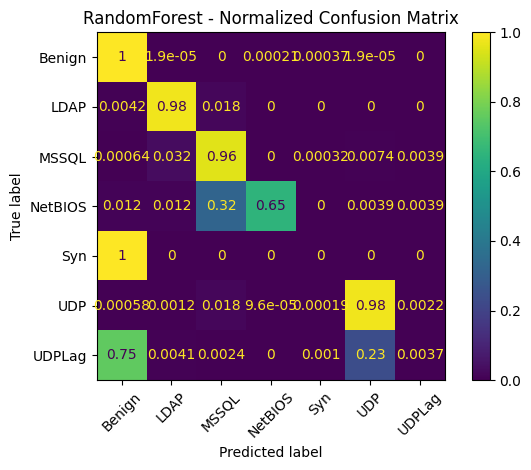

In [22]:

#21 — Confusion Matrix


import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

best_test_pred = best_model.predict(
    X_test_known_sel
)

plt.figure(figsize=(11,9))

ConfusionMatrixDisplay.from_predictions(
    y_test_known_multi,
    best_test_pred,
    labels=present_classes,
    display_labels=le.inverse_transform(
        present_classes
    ),
    normalize='true',
    xticks_rotation=45,
    cmap=None
)

plt.title(
    f"{best_model_name} - Normalized Confusion Matrix"
)

plt.tight_layout()
plt.show()

In [23]:

#22 — Binary Classification Dataset


y_train_binary = (
    train_df.loc[X_train.index, 'Label'] != 'Benign'
).astype(int)

y_val_binary = (
    train_df.loc[X_val.index, 'Label'] != 'Benign'
).astype(int)

print("Binary training distribution:")
print(y_train_binary.value_counts())

print("\nBinary validation distribution:")
print(y_val_binary.value_counts())

Binary training distribution:
Label
1    62994
0    37142
Name: count, dtype: int64

Binary validation distribution:
Label
1    15749
0     9285
Name: count, dtype: int64


In [24]:

#23 — Binary Models


binary_models = {

    "Binary_RF": RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED
    ),

    "Binary_XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        n_jobs=-1,
        random_state=SEED
    ),

    "Binary_LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED,
        verbosity=-1
    )
}

binary_trained = {}

for name, model in binary_models.items():

    print("Training:", name)

    model.fit(
        X_train_sel,
        y_train_binary
    )

    binary_trained[name] = model

Training: Binary_RF
Training: Binary_XGBoost
Training: Binary_LightGBM


In [25]:

#23 — Binary Models


binary_models = {

    "Binary_RF": RandomForestClassifier(
        n_estimators=300,
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED
    ),

    "Binary_XGBoost": XGBClassifier(
        n_estimators=300,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='binary:logistic',
        eval_metric='logloss',
        tree_method='hist',
        n_jobs=-1,
        random_state=SEED
    ),

    "Binary_LightGBM": LGBMClassifier(
        n_estimators=300,
        learning_rate=0.05,
        num_leaves=31,
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED,
        verbosity=-1
    )
}

binary_trained = {}

for name, model in binary_models.items():

    print("Training:", name)

    model.fit(
        X_train_sel,
        y_train_binary
    )

    binary_trained[name] = model

Training: Binary_RF
Training: Binary_XGBoost
Training: Binary_LightGBM


In [26]:

#24 — Binary Validation


binary_validation_results = []

for name, model in binary_trained.items():

    pred = model.predict(
        X_val_sel
    )

    binary_validation_results.append({

        "Model": name,

        "Accuracy": accuracy_score(
            y_val_binary,
            pred
        ),

        "Precision": precision_score(
            y_val_binary,
            pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_val_binary,
            pred,
            zero_division=0
        ),

        "F1": f1_score(
            y_val_binary,
            pred,
            zero_division=0
        )
    })

binary_validation_df = pd.DataFrame(
    binary_validation_results
)

print(binary_validation_df)

best_binary_name = binary_validation_df.loc[
    binary_validation_df["F1"].idxmax(),
    "Model"
]

best_binary_model = binary_trained[
    best_binary_name
]

print("\nBest binary model:", best_binary_name)

             Model  Accuracy  Precision    Recall        F1
0        Binary_RF  0.999361   0.999809  0.999175  0.999492
1   Binary_XGBoost  0.999481   0.999682  0.999492  0.999587
2  Binary_LightGBM  0.999640   0.999873  0.999556  0.999714

Best binary model: Binary_LightGBM


In [27]:

#26 — Isolation Forest


from sklearn.ensemble import IsolationForest


# Training data containing ONLY benign flows


benign_train_mask = (
    train_df.loc[X_train.index, 'Label'] == 'Benign'
)

X_train_benign = X_train_sel[
    benign_train_mask
]

print(
    "Benign training samples:",
    len(X_train_benign)
)

iso = IsolationForest(
    n_estimators=300,
    contamination='auto',
    n_jobs=-1,
    random_state=SEED
)

iso.fit(
    X_train_benign
)

print("Isolation Forest trained.")

Benign training samples: 37142
Isolation Forest trained.


In [28]:

#27 — Isolation Scores


# Higher score = more normal
# Lower score = more anomalous

train_benign_scores = iso.decision_function(
    X_train_benign
)

val_scores = iso.decision_function(
    X_val_sel
)

known_test_scores = iso.decision_function(
    X_test_known_sel
)

zeroday_test_scores = iso.decision_function(
    X_test_zeroday_sel
)

print("Score statistics:")
print(
    pd.Series(train_benign_scores).describe()
)

Score statistics:
count    37142.000000
mean         0.110351
std          0.087410
min         -0.260402
25%          0.066178
50%          0.160001
75%          0.170761
max          0.176281
dtype: float64


In [29]:

#28 — Isolation Forest Threshold Calibration


# Validation benign samples only
val_benign_mask = (
    y_val_binary.values == 0
)

val_benign_scores = val_scores[
    val_benign_mask
]

# Candidate false-positive rates
candidate_fpr = [
    0.01,
    0.02,
    0.03,
    0.05,
    0.10
]

thresholds = {}

for fpr in candidate_fpr:

    threshold = np.quantile(
        val_benign_scores,
        fpr
    )

    thresholds[fpr] = threshold

    print(
        f"Target FPR={fpr:.2%} "
        f"Threshold={threshold:.6f}"
    )

Target FPR=1.00% Threshold=-0.169235
Target FPR=2.00% Threshold=-0.133466
Target FPR=3.00% Threshold=-0.113232
Target FPR=5.00% Threshold=-0.083783
Target FPR=10.00% Threshold=-0.038011


In [30]:

#29 — Isolation Forest Validation Analysis


from sklearn.metrics import confusion_matrix

iso_validation_results = []

for target_fpr, threshold in thresholds.items():

    pred = (
        val_scores < threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val_binary,
        pred,
        labels=[0,1]
    ).ravel()

    actual_fpr = fp / (fp + tn)
    recall = tp / (tp + fn)

    iso_validation_results.append({

        "Target_FPR": target_fpr,

        "Threshold": threshold,

        "Actual_FPR": actual_fpr,

        "Recall": recall,

        "F1": f1_score(
            y_val_binary,
            pred,
            zero_division=0
        )
    })

iso_validation_df = pd.DataFrame(
    iso_validation_results
)

print(iso_validation_df)

   Target_FPR  Threshold  Actual_FPR    Recall        F1
0        0.01  -0.169235    0.010016  0.108007  0.193924
1        0.02  -0.133466    0.020032  0.131945  0.230722
2        0.03  -0.113232    0.030048  0.159756  0.271355
3        0.05  -0.083783    0.050081  0.178424  0.295416
4        0.10  -0.038011    0.100054  0.447013  0.593642


In [31]:

#30 — Select Isolation Threshold


best_threshold_row = iso_validation_df.loc[
    iso_validation_df["F1"].idxmax()
]

ISO_THRESHOLD = best_threshold_row[
    "Threshold"
]

print(
    "Selected threshold:",
    ISO_THRESHOLD
)

print(
    "Validation F1:",
    best_threshold_row["F1"]
)

print(
    "Validation FPR:",
    best_threshold_row["Actual_FPR"]
)

Selected threshold: -0.03801052575558374
Validation F1: 0.5936419596930601
Validation FPR: 0.10005385029617662


In [32]:

#31 — Zero-Day Detection


iso_known_pred = (
    known_test_scores < ISO_THRESHOLD
).astype(int)

iso_zeroday_pred = (
    zeroday_test_scores < ISO_THRESHOLD
).astype(int)

print("Known test:")
print(
    classification_report(
        y_test_known_bin,
        iso_known_pred,
        target_names=[
            "Benign",
            "Attack"
        ],
        zero_division=0
    )
)

print("\nZero-day test:")

print(
    classification_report(
        y_test_zeroday_bin,
        iso_zeroday_pred,
        target_names=[
            "Benign",
            "Zero-Day Attack"
        ],
        zero_division=0
    )
)

Known test:
              precision    recall  f1-score   support

      Benign       0.89      0.93      0.91     51404
      Attack       0.86      0.78      0.82     28075

    accuracy                           0.88     79479
   macro avg       0.87      0.85      0.86     79479
weighted avg       0.88      0.88      0.88     79479


Zero-day test:


                 precision    recall  f1-score   support

         Benign       0.00      0.00      0.00         0
Zero-Day Attack       1.00      0.99      1.00    226722

       accuracy                           0.99    226722
      macro avg       0.50      0.50      0.50    226722
   weighted avg       1.00      0.99      1.00    226722



In [33]:

#32 — Per Zero-Day Attack Detection


zero_day_labels = (
    test_zeroday_df['Label'].values
)

zero_day_results = []

for attack in sorted(
    np.unique(zero_day_labels)
):

    mask = (
        zero_day_labels == attack
    )

    true_attack = np.ones(
        mask.sum(),
        dtype=int
    )

    predicted_attack = iso_zeroday_pred[
        mask
    ]

    detection_rate = (
        predicted_attack.mean()
    )

    zero_day_results.append({

        "Attack": attack,

        "Samples": mask.sum(),

        "Detection_Rate":
            detection_rate,

        "Miss_Rate":
           1 - detection_rate
    })

zero_day_results_df = pd.DataFrame(
    zero_day_results
)

print(zero_day_results_df)

    Attack  Samples  Detection_Rate  Miss_Rate
0      DNS     3669        0.941128   0.058872
1      NTP   121368        0.992370   0.007630
2     SNMP     2717        0.998160   0.001840
3     TFTP    98917        0.996694   0.003306
4  WebDDoS       51        0.039216   0.960784


In [34]:

#33 — Hybrid Two-Stage Detector


def hybrid_predict(
    anomaly_scores,
    classifier,
    X_classifier,
    threshold,
    confidence_threshold
):

    classifier_probabilities = (
        classifier.predict_proba(
            X_classifier
        )
    )

    classifier_predictions = (
        np.argmax(
            classifier_probabilities,
            axis=1
        )
    )

    classifier_confidence = (
        np.max(
            classifier_probabilities,
            axis=1
        )
    )

    final_predictions = []

    for i in range(
        len(anomaly_scores)
    ):

        # Stage 1: anomaly detector
        if anomaly_scores[i] >= threshold:

            final_predictions.append(
                "Benign"
            )

        else:

            # Stage 2: classifier confidence
            if (
                classifier_confidence[i]
                >= confidence_threshold
            ):

                predicted_class = (
                    le.inverse_transform(
                        [classifier_predictions[i]]
                    )[0]
                )

                final_predictions.append(
                    predicted_class
                )

            else:

                final_predictions.append(
                    "Unknown Attack"
                )

    return np.array(
        final_predictions
    )

In [35]:

#34 — Hybrid Confidence Threshold Calibration


val_anomaly_scores = val_scores

confidence_candidates = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.90,
    0.95
]

hybrid_validation_results = []

for confidence_threshold in confidence_candidates:

    predictions = hybrid_predict(
        val_anomaly_scores,
        best_model,
        X_val_sel,
        ISO_THRESHOLD,
        confidence_threshold
    )

    # Binary interpretation:
    # Benign = 0
    # Anything else = Attack
    binary_pred = (
        predictions != "Benign"
    ).astype(int)

    hybrid_validation_results.append({

        "Confidence_Threshold":
            confidence_threshold,

        "Accuracy":
            accuracy_score(
                y_val_binary,
                binary_pred
            ),

        "Precision":
            precision_score(
                y_val_binary,
                binary_pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_val_binary,
                binary_pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_val_binary,
                binary_pred,
                zero_division=0
            )
    })

hybrid_validation_df = pd.DataFrame(
    hybrid_validation_results
)

print(hybrid_validation_df)

   Confidence_Threshold  Accuracy  Precision    Recall        F1
0                  0.50  0.652113   1.000000  0.447013  0.617842
1                  0.60  0.652113   1.000000  0.447013  0.617842
2                  0.70  0.652033   0.999716  0.447013  0.617788
3                  0.80  0.652033   0.999716  0.447013  0.617788
4                  0.90  0.651674   0.998440  0.447013  0.617544
5                  0.95  0.651194   0.996744  0.447013  0.617219


In [36]:

#35 — Select Hybrid Threshold


best_confidence = hybrid_validation_df.loc[
    hybrid_validation_df["F1"].idxmax(),
    "Confidence_Threshold"
]

print(
    "Selected confidence threshold:",
    best_confidence
)

Selected confidence threshold: 0.5


In [37]:

#36 — Hybrid Known-Test Evaluation


hybrid_known_predictions = hybrid_predict(
    known_test_scores,
    best_model,
    X_test_known_sel,
    ISO_THRESHOLD,
    best_confidence
)

print(
    pd.Series(
        hybrid_known_predictions
    ).value_counts()
)

Benign            58623
UDP               12306
MSSQL              6316
LDAP               1641
NetBIOS             339
Portmap              99
UDPLag               82
Unknown Attack       68
Syn                   5
Name: count, dtype: int64


In [38]:

#37 — Hybrid Zero-Day Evaluation


hybrid_zeroday_predictions = hybrid_predict(
    zeroday_test_scores,
    best_model,
    X_test_zeroday_sel,
    ISO_THRESHOLD,
    best_confidence
)

print(
    pd.Series(
        hybrid_zeroday_predictions
    ).value_counts()
)

UDP               111590
MSSQL              99349
Unknown Attack      8541
LDAP                4103
Benign              2678
NetBIOS              330
Portmap              107
UDPLag                14
Syn                   10
Name: count, dtype: int64


In [39]:

#38 — Hybrid Zero-Day Detection Metrics


hybrid_zeroday_binary = (
    hybrid_zeroday_predictions != "Benign"
).astype(int)

print(
    classification_report(
        y_test_zeroday_bin,
        hybrid_zeroday_binary,
        target_names=[
            "Benign",
            "Zero-Day Attack"
        ],
        zero_division=0
    )
)

zero_day_detection_rate = (
    hybrid_zeroday_binary.mean()
)

print(
    "Zero-day detection rate:",
    round(
        zero_day_detection_rate,
       4
    )
)

                 precision    recall  f1-score   support

         Benign       0.00      0.00      0.00         0
Zero-Day Attack       1.00      0.99      0.99    226722

       accuracy                           0.99    226722
      macro avg       0.50      0.49      0.50    226722
   weighted avg       1.00      0.99      0.99    226722

Zero-day detection rate: 0.9882


In [40]:

#39 — Hybrid Per-Attack Results


hybrid_zero_day_results = []

for attack in sorted(
    np.unique(zero_day_labels)
):

    mask = (
        zero_day_labels == attack
    )

    predictions = (
        hybrid_zeroday_predictions[mask]
    )

    detected = (
        predictions != "Benign"
    )

    hybrid_zero_day_results.append({

        "Attack": attack,

        "Samples": mask.sum(),

        "Detected":
            detected.sum(),

        "Detection_Rate":
            detected.mean(),

        "Unknown_Rate":
            (
                predictions == "Unknown Attack"
            ).mean(),

        "Forced_Known_Rate":
            (
                ~np.isin(
                    predictions,
                    ["Benign", "Unknown Attack"]
                )
            ).mean()
    })

hybrid_zero_day_results_df = pd.DataFrame(
    hybrid_zero_day_results
)

print(
    hybrid_zero_day_results_df
)

    Attack  Samples  Detected  Detection_Rate  Unknown_Rate  Forced_Known_Rate
0      DNS     3669      3403        0.927501      0.013628           0.913873
1      NTP   121368    119343        0.983315      0.066138           0.917178
2     SNMP     2717      2712        0.998160      0.000736           0.997424
3     TFTP    98917     98586        0.996654      0.004671           0.991983
4  WebDDoS       51         0        0.000000      0.000000           0.000000


In [41]:

#40 — Zero-Day Method Comparison


classifier_zeroday_pred = (
    best_model.predict(
        X_test_zeroday_sel
    )
)

classifier_zeroday_labels = (
    le.inverse_transform(
        classifier_zeroday_pred
    )
)

classifier_attack_detection = (
    classifier_zeroday_labels != "Benign"
).mean()

if_attack_detection = (
    iso_zeroday_pred.mean()
)

hybrid_attack_detection = (
    hybrid_zeroday_binary.mean()
)

comparison = pd.DataFrame({

    "Method": [
        "Multiclass Classifier",
        "Isolation Forest",
        "Hybrid"
    ],

    "Zero_Day_Detection_Rate": [
        classifier_attack_detection,
        if_attack_detection,
        hybrid_attack_detection
    ]
})

print(comparison)

                  Method  Zero_Day_Detection_Rate
0  Multiclass Classifier                 0.985846
1       Isolation Forest                 0.993283
2                 Hybrid                 0.988188


In [42]:

#41 — Ablation Study


ablation = []


# A. Classifier only


classifier_binary = (
    best_model.predict(
        X_test_known_sel
    ) != le.transform(
        ["Benign"]
    )[0]
).astype(int)

ablation.append({

    "Configuration":
        "Classifier Only",

    "Known_Attack_F1":
        f1_score(
            y_test_known_bin,
            classifier_binary,
            zero_division=0
        )
})


# B. Isolation Forest only


ablation.append({

    "Configuration":
        "Isolation Forest Only",

    "Known_Attack_F1":
        f1_score(
            y_test_known_bin,
            iso_known_pred,
            zero_division=0
        )
})


# C. Hybrid


hybrid_known_binary = (
    hybrid_known_predictions != "Benign"
).astype(int)

ablation.append({

    "Configuration":
        "Hybrid",

    "Known_Attack_F1":
        f1_score(
            y_test_known_bin,
            hybrid_known_binary,
            zero_division=0
        )
})

ablation_df = pd.DataFrame(
    ablation
)

print(ablation_df)

           Configuration  Known_Attack_F1
0        Classifier Only         0.851318
1  Isolation Forest Only         0.817169
2                 Hybrid         0.852057


In [43]:

#42 — Feature Selection Ablation


feature_ablation = []

for k in FEATURE_COUNTS:

    features = feature_sets[k]

    model = RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED
    )

    model.fit(
        X_train[features],
        y_train_multi
    )

    pred = model.predict(
        X_test_known[features]
    )

    feature_ablation.append({

        "Features": k,

        "Accuracy":
            accuracy_score(
                y_test_known_multi,
                pred
            ),

        "Macro_F1":
            f1_score(
                y_test_known_multi,
                pred,
                average='macro',
                zero_division=0
            ),

        "Weighted_F1":
            f1_score(
                y_test_known_multi,
                pred,
                average='weighted',
                zero_division=0
            )
    })

feature_ablation_df = pd.DataFrame(
    feature_ablation
)

print(feature_ablation_df)

   Features  Accuracy  Macro_F1  Weighted_F1
0        10  0.871614  0.551102     0.818191
1        20  0.871312  0.550514     0.818019
2        25  0.871299  0.546396     0.817381
3        30  0.871174  0.546562     0.817325
4        40  0.871350  0.546757     0.817475
5        50  0.871501  0.547446     0.817594


In [44]:

#42 — Feature Selection Ablation


feature_ablation = []

for k in FEATURE_COUNTS:

    features = feature_sets[k]

    model = RandomForestClassifier(
        n_estimators=200,
        class_weight='balanced',
        n_jobs=-1,
        random_state=SEED
    )

    model.fit(
        X_train[features],
        y_train_multi
    )

    pred = model.predict(
        X_test_known[features]
    )

    feature_ablation.append({

        "Features": k,

        "Accuracy":
            accuracy_score(
                y_test_known_multi,
                pred
            ),

        "Macro_F1":
            f1_score(
                y_test_known_multi,
                pred,
                average='macro',
                zero_division=0
            ),

        "Weighted_F1":
            f1_score(
                y_test_known_multi,
                pred,
                average='weighted',
                zero_division=0
            )
    })

feature_ablation_df = pd.DataFrame(
    feature_ablation
)

print(feature_ablation_df)

   Features  Accuracy  Macro_F1  Weighted_F1
0        10  0.871614  0.551102     0.818191
1        20  0.871312  0.550514     0.818019
2        25  0.871299  0.546396     0.817381
3        30  0.871174  0.546562     0.817325
4        40  0.871350  0.546757     0.817475
5        50  0.871501  0.547446     0.817594


In [45]:

#43 — Robust Inference Latency


LATENCY_SAMPLES = min(
   10000,
    len(X_test_known_sel)
)

X_latency = X_test_known_sel.iloc[
    :LATENCY_SAMPLES
]

latency_results = []

for name, model in trained_models.items():

    measurements = []

    # Warm-up
    model.predict(
        X_latency.iloc[:100]
    )

    for _ in range(5):

        start = time.perf_counter()

        model.predict(
            X_latency
        )

        elapsed = (
            time.perf_counter()
            - start
        )

        measurements.append(
            elapsed
        )

    mean_time = np.mean(
        measurements
    )

    latency_results.append({

        "Model": name,

        "Samples": LATENCY_SAMPLES,

        "Mean_Time_sec":
            mean_time,

        "Samples_per_sec":
            LATENCY_SAMPLES / mean_time,

        "Latency_ms_per_sample":
            (
                mean_time
                / LATENCY_SAMPLES
                *1000
            )
    })

latency_df = pd.DataFrame(
    latency_results
)

print(latency_df)

          Model  Samples  Mean_Time_sec  Samples_per_sec  \
0  DecisionTree    10000       0.006140     1.628781e+06   
1  RandomForest    10000       0.159627     6.264618e+04   
2       XGBoost    10000       0.122151     8.186603e+04   
3      LightGBM    10000       0.648516     1.541982e+04   

   Latency_ms_per_sample  
0               0.000614  
1               0.015963  
2               0.012215  
3               0.064852  


In [46]:

#44 — SHAP Explainability


import shap

print(
    "Explaining:",
    best_model_name
)

# Use a manageable sample
SHAP_SAMPLE = min(
   2000,
    len(X_test_known_sel)
)

X_shap = X_test_known_sel.sample(
    SHAP_SAMPLE,
    random_state=SEED
)

explainer = shap.TreeExplainer(
    best_model
)

shap_values = explainer.shap_values(
    X_shap
)

print("SHAP calculated.")

Explaining: RandomForest
SHAP calculated.


C:\Users\Atharva\AppData\Local\Temp\ipykernel_132564\3165815129.py:4: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(
d:\CN Paper\.venv\lib\site-packages\shap\plots\_beeswarm.py:723: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
d:\CN Paper\.venv\lib\site-packages\shap\plots\_beeswarm.py:743: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  summary_legacy(
d:\CN Paper\.venv\lib\site-packages\shap\plots\_beeswarm.py:743: Future

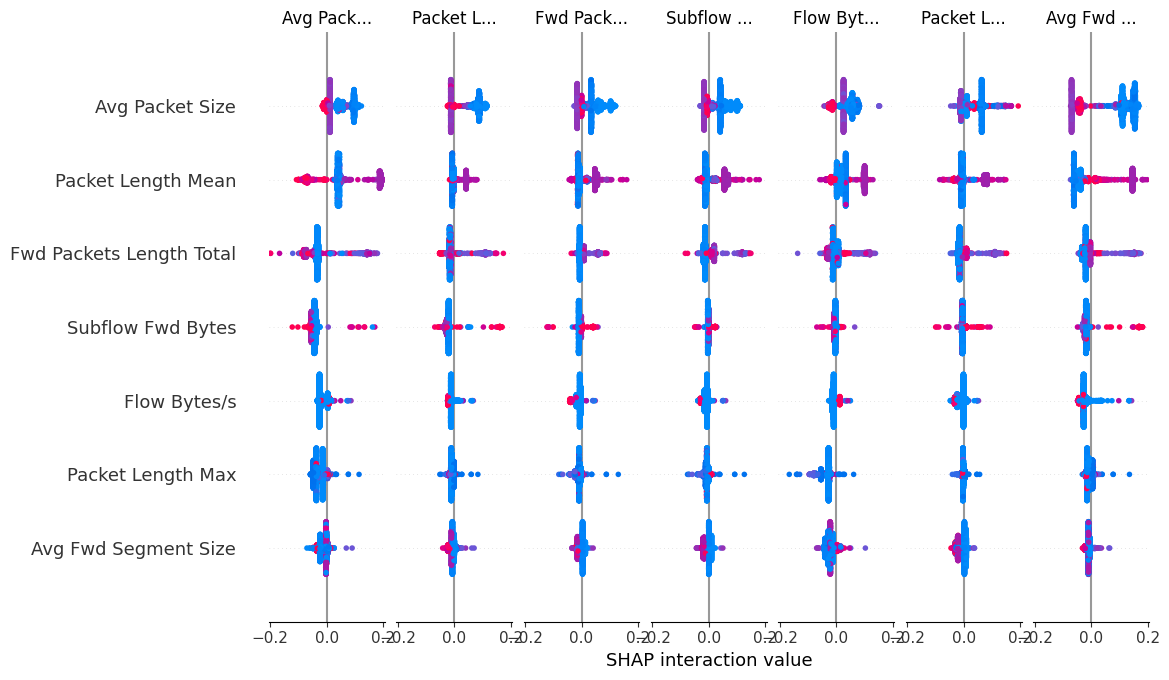

In [47]:

#45 — SHAP Summary


shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=X_shap.columns
)

In [48]:

#46 — Feature Importance


if hasattr(
    best_model,
    "feature_importances_"
):

    importance_df = pd.DataFrame({

        "Feature":
            X_train_sel.columns,

        "Importance":
            best_model.feature_importances_

    }).sort_values(
        "Importance",
        ascending=False
    )

    print(
        importance_df.head(20)
    )

                     Feature  Importance
8          Packet Length Min    0.106063
0            Avg Packet Size    0.105064
9      Fwd Packet Length Min    0.082259
5     Fwd Packet Length Mean    0.073304
4       Avg Fwd Segment Size    0.069906
3               Flow Bytes/s    0.053473
6         Packet Length Mean    0.050950
10     Fwd Packet Length Max    0.047672
7          Packet Length Max    0.040857
12             Flow IAT Mean    0.040243
1          Subflow Fwd Bytes    0.039893
2   Fwd Packets Length Total    0.037422
18        Init Fwd Win Bytes    0.037207
14            Flow Packets/s    0.035372
19             Fwd IAT Total    0.032099
13             Flow Duration    0.030972
11              Flow IAT Max    0.030039
16              Flow IAT Std    0.029743
17               Fwd IAT Max    0.028764
15             Fwd Packets/s    0.028699


In [49]:

#46 — Feature Importance


if hasattr(
    best_model,
    "feature_importances_"
):

    importance_df = pd.DataFrame({

        "Feature":
            X_train_sel.columns,

        "Importance":
            best_model.feature_importances_

    }).sort_values(
        "Importance",
        ascending=False
    )

    print(
        importance_df.head(20)
    )

                     Feature  Importance
8          Packet Length Min    0.106063
0            Avg Packet Size    0.105064
9      Fwd Packet Length Min    0.082259
5     Fwd Packet Length Mean    0.073304
4       Avg Fwd Segment Size    0.069906
3               Flow Bytes/s    0.053473
6         Packet Length Mean    0.050950
10     Fwd Packet Length Max    0.047672
7          Packet Length Max    0.040857
12             Flow IAT Mean    0.040243
1          Subflow Fwd Bytes    0.039893
2   Fwd Packets Length Total    0.037422
18        Init Fwd Win Bytes    0.037207
14            Flow Packets/s    0.035372
19             Fwd IAT Total    0.032099
13             Flow Duration    0.030972
11              Flow IAT Max    0.030039
16              Flow IAT Std    0.029743
17               Fwd IAT Max    0.028764
15             Fwd Packets/s    0.028699


In [50]:

#48 — Final Research Results


print("==============================================")
print("FINAL MULTICLASS RESULTS")
print("==============================================")

display(
    test_results_df.sort_values(
        "Macro_F1",
        ascending=False
    )
)

print("\n==============================================")
print("ZERO-DAY DETECTION")
print("==============================================")

display(
    zero_day_results_df
)

print("\n==============================================")
print("HYBRID ZERO-DAY RESULTS")
print("==============================================")

display(
    hybrid_zero_day_results_df
)

print("\n==============================================")
print("FEATURE ABLATION")
print("==============================================")

display(
    feature_ablation_df
)

print("\n==============================================")
print("LATENCY")
print("==============================================")

display(
    latency_df
)

FINAL MULTICLASS RESULTS


,Model,Accuracy,Macro_Precision,Macro_Recall,Macro_F1,Weighted_F1,Latency_ms_per_sample
1,RandomForest,0.871350,0.607119,0.559313,0.550218,0.817973,0.011151
3,LightGBM,0.869563,0.617863,0.557738,0.546963,0.820757,0.058288
2,XGBoost,0.868984,0.592348,0.557572,0.543801,0.816157,0.011685
0,DecisionTree,0.862706,0.591155,0.559804,0.542598,0.813201,0.000335



ZERO-DAY DETECTION


,Attack,Samples,Detection_Rate,Miss_Rate
0,DNS,3669,0.941128,0.058872
1,NTP,121368,0.992370,0.007630
2,SNMP,2717,0.998160,0.001840
3,TFTP,98917,0.996694,0.003306
4,WebDDoS,51,0.039216,0.960784



HYBRID ZERO-DAY RESULTS


,Attack,Samples,Detected,Detection_Rate,Unknown_Rate,Forced_Known_Rate
0,DNS,3669,3403,0.927501,0.013628,0.913873
1,NTP,121368,119343,0.983315,0.066138,0.917178
2,SNMP,2717,2712,0.998160,0.000736,0.997424
3,TFTP,98917,98586,0.996654,0.004671,0.991983
4,WebDDoS,51,0,0.000000,0.000000,0.000000



FEATURE ABLATION


,Features,Accuracy,Macro_F1,Weighted_F1
0,10,0.871614,0.551102,0.818191
1,20,0.871312,0.550514,0.818019
2,25,0.871299,0.546396,0.817381
3,30,0.871174,0.546562,0.817325
4,40,0.871350,0.546757,0.817475
5,50,0.871501,0.547446,0.817594



LATENCY


,Model,Samples,Mean_Time_sec,Samples_per_sec,Latency_ms_per_sample
0,DecisionTree,10000,0.006140,1.628781e+06,0.000614
1,RandomForest,10000,0.159627,6.264618e+04,0.015963
2,XGBoost,10000,0.122151,8.186603e+04,0.012215
3,LightGBM,10000,0.648516,1.541982e+04,0.064852


In [51]:

#49 — Binary Official Test Evaluation


from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    confusion_matrix
)

binary_test_results = []

for name, model in binary_trained.items():

    pred = model.predict(
        X_test_known_sel
    )

    proba = model.predict_proba(
        X_test_known_sel
    )[:,1]

    binary_test_results.append({

        "Model": name,

        "Accuracy":
            accuracy_score(
                y_test_known_bin,
                pred
            ),

        "Precision":
            precision_score(
                y_test_known_bin,
                pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_test_known_bin,
                pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_test_known_bin,
                pred,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                y_test_known_bin,
                proba
            )
    })


binary_test_df = pd.DataFrame(
    binary_test_results
)

print("Binary Official Test Results")
print("============================")

print(
    binary_test_df.sort_values(
        "F1",
        ascending=False
    )
)

Binary Official Test Results
             Model  Accuracy  Precision    Recall        F1   ROC_AUC
2  Binary_LightGBM  0.988160   0.997725  0.968691  0.982994  0.999851
1   Binary_XGBoost  0.933542   0.997512  0.813891  0.896395  0.997235
0        Binary_RF  0.908781   0.998230  0.743081  0.851962  0.998181


In [52]:

#50 — Open-Set Binary Test



# Build an open-set test dataset


test_open_df = pd.concat(
    [
        test_known_df,
        test_zeroday_df
    ],
    ignore_index=True
)

X_test_open = test_open_df[
    top_features
].copy()

y_test_open_binary = (
    test_open_df["Label"] != "Benign"
).astype(int).values

print("Open-set test shape:")
print(X_test_open.shape)

print("\nClass distribution:")
print(
    test_open_df["Label"].value_counts()
)


# Evaluate binary classifiers


open_binary_results = []

for name, model in binary_trained.items():

    pred = model.predict(
        X_test_open
    )

    proba = model.predict_proba(
        X_test_open
    )[:,1]

    open_binary_results.append({

        "Model": name,

        "Accuracy":
            accuracy_score(
                y_test_open_binary,
                pred
            ),

        "Precision":
            precision_score(
                y_test_open_binary,
                pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_test_open_binary,
                pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_test_open_binary,
                pred,
                zero_division=0
            ),

        "ROC_AUC":
            roc_auc_score(
                y_test_open_binary,
                proba
            )
    })

open_binary_df = pd.DataFrame(
    open_binary_results
)

print("\nOpen-Set Binary Results")
print("=======================")

print(open_binary_df)

Open-set test shape:
(306201, 20)

Class distribution:
Label
NTP        121368
TFTP        98917
Benign      51404
UDP         10420
UDPLag       8872
MSSQL        6212
DNS          3669
SNMP         2717
LDAP         1440
NetBIOS       598
Syn           533
WebDDoS        51
Name: count, dtype: int64

Open-Set Binary Results
             Model  Accuracy  Precision    Recall        F1   ROC_AUC
0        Binary_RF  0.938377   0.999843  0.926090  0.961555  0.998879
1   Binary_XGBoost  0.971130   0.999768  0.965529  0.982351  0.999166
2  Binary_LightGBM  0.961600   0.999745  0.954097  0.976388  0.999750


In [53]:

#51 — Zero-Day Detection Operating Points


from sklearn.metrics import (
    recall_score,
    confusion_matrix
)

FPR_TARGETS = [
    0.001,
    0.005,
    0.01,
    0.02,
    0.03,
    0.05,
    0.10
]

operating_results = []

# Validation benign scores
val_benign_scores = val_scores[
    y_val_binary.values == 0
]

for target_fpr in FPR_TARGETS:

    threshold = np.quantile(
        val_benign_scores,
        target_fpr
    )

    # Zero-day detection
    zero_day_pred = (
        zeroday_test_scores < threshold
    ).astype(int)

    zero_day_recall = (
        zero_day_pred.mean()
    )

    # Known-test benign false-positive rate
    known_benign_mask = (
        y_test_known_bin.values == 0
    )

    known_benign_pred = (
        known_test_scores[known_benign_mask]
        < threshold
    ).astype(int)

    benign_fpr = (
        known_benign_pred.mean()
    )

    operating_results.append({

        "Target_FPR":
            target_fpr,

        "Threshold":
            threshold,

        "Known_Benign_FPR":
            benign_fpr,

        "Zero_Day_Recall":
            zero_day_recall
    })

operating_df = pd.DataFrame(
    operating_results
)

print(operating_df)

   Target_FPR  Threshold  Known_Benign_FPR  Zero_Day_Recall
0       0.001  -0.215533          0.001420         0.022080
1       0.005  -0.184422          0.004397         0.213213
2       0.010  -0.169235          0.007101         0.294691
3       0.020  -0.133466          0.014104         0.869664
4       0.030  -0.113232          0.020465         0.943808
5       0.050  -0.083783          0.032313         0.980399
6       0.100  -0.038011          0.070598         0.993283


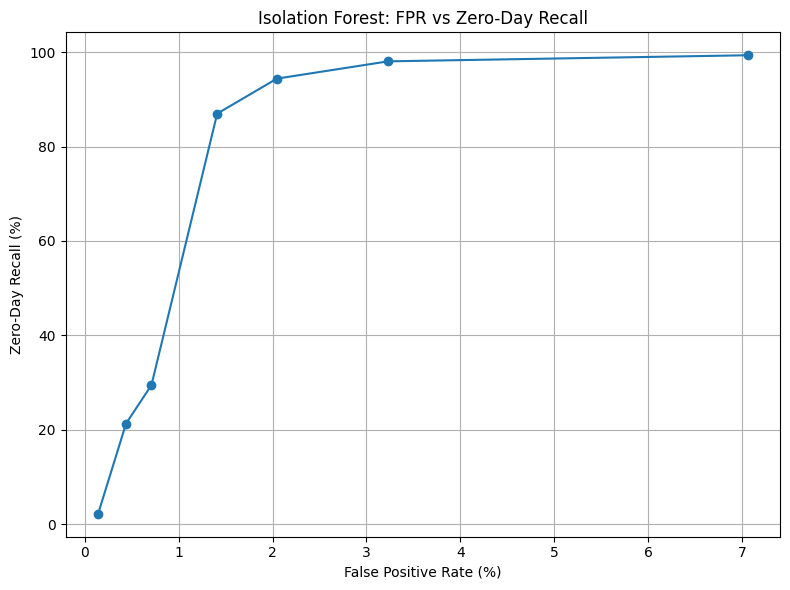

In [54]:

#52 — FPR vs Zero-Day Recall


import matplotlib.pyplot as plt

plt.figure(figsize=(8,6))

plt.plot(
    operating_df["Known_Benign_FPR"] *100,
    operating_df["Zero_Day_Recall"] *100,
    marker="o"
)

plt.xlabel("False Positive Rate (%)")
plt.ylabel("Zero-Day Recall (%)")
plt.title(
    "Isolation Forest: FPR vs Zero-Day Recall"
)

plt.grid(True)
plt.tight_layout()
plt.show()

In [55]:

#53 — Bootstrap Confidence Intervals


def bootstrap_ci_binary(
    predictions,
    n_bootstrap=2000,
    confidence=0.95,
    seed=42
):

    rng = np.random.default_rng(seed)

    predictions = np.asarray(
        predictions
    )

    scores = []

    n = len(predictions)

    for _ in range(n_bootstrap):

        sample = rng.choice(
            predictions,
            size=n,
            replace=True
        )

        scores.append(
            sample.mean()
        )

    alpha =1 - confidence

    lower = np.percentile(
        scores,
       100 * alpha /2
    )

    upper = np.percentile(
        scores,
       100 * (1 - alpha /2)
    )

    return (
        predictions.mean(),
        lower,
        upper
    )


ci_results = []

for attack in sorted(
    np.unique(zero_day_labels)
):

    mask = (
        zero_day_labels == attack
    )

    predictions = (
        iso_zeroday_pred[mask]
    )

    mean, lower, upper = (
        bootstrap_ci_binary(
            predictions,
            seed=SEED
        )
    )

    ci_results.append({

        "Attack":
            attack,

        "Samples":
            len(predictions),

        "Detection_Rate":
            mean,

        "CI_Lower":
            lower,

        "CI_Upper":
            upper
    })

zero_day_ci_df = pd.DataFrame(
    ci_results
)

print(
    zero_day_ci_df
)

    Attack  Samples  Detection_Rate  CI_Lower  CI_Upper
0      DNS     3669        0.941128  0.933497  0.948487
1      NTP   121368        0.992370  0.991868  0.992865
2     SNMP     2717        0.998160  0.996319  0.999632
3     TFTP    98917        0.996694  0.996310  0.997038
4  WebDDoS       51        0.039216  0.000000  0.098039


In [56]:

#54 — Exact Overlap Sensitivity Analysis



# Create hashes for selected features


train_selected_hashes = set(
    pd.util.hash_pandas_object(
        X_full_train[top_features],
        index=False
    ).values
)

known_test_hashes = (
    pd.util.hash_pandas_object(
        X_test_known_sel,
        index=False
    )
)

overlap_mask = np.array([
    h in train_selected_hashes
    for h in known_test_hashes.values
])

print(
    "Overlapping known-test samples:",
    overlap_mask.sum()
)

print(
    "Non-overlapping known-test samples:",
    (~overlap_mask).sum()
)

print(
    "Overlap percentage:",
    round(
        overlap_mask.mean() *100,
       4
    ),
    "%"
)


# Evaluate best model on non-overlapping samples


X_known_no_overlap = (
    X_test_known_sel.loc[
        ~overlap_mask
    ]
)

y_known_no_overlap = (
    y_test_known_multi.loc[
        ~overlap_mask
    ]
)

no_overlap_pred = best_model.predict(
    X_known_no_overlap
)

overlap_sensitivity = {

    "Original_Macro_F1":
        f1_score(
            y_test_known_multi,
            best_model.predict(
                X_test_known_sel
            ),
            average="macro",
            zero_division=0
        ),

    "No_Overlap_Macro_F1":
        f1_score(
            y_known_no_overlap,
            no_overlap_pred,
            average="macro",
            zero_division=0
        )
}

print(
    pd.DataFrame(
        [overlap_sensitivity]
    )
)

Overlapping known-test samples: 11074
Non-overlapping known-test samples: 68405
Overlap percentage: 13.9332 %
   Original_Macro_F1  No_Overlap_Macro_F1
0           0.550218             0.509014


In [57]:

#55 — Proper Open-Set Anomaly Evaluation



# Use ALL benign test samples


test_benign_df = test_df[
    test_df["Label"] == "Benign"
].copy()


# Combine benign + zero-day attacks


open_anomaly_df = pd.concat(
    [
        test_benign_df,
        test_zeroday_df
    ],
    ignore_index=True
)

X_open_anomaly = (
    open_anomaly_df[top_features]
    .copy()
)

y_open_anomaly = (
    open_anomaly_df["Label"] != "Benign"
).astype(int).values


# Isolation Forest


open_anomaly_scores = (
    iso.decision_function(
        X_open_anomaly
    )
)

open_anomaly_pred = (
    open_anomaly_scores
    < ISO_THRESHOLD
).astype(int)

print(
    classification_report(
        y_open_anomaly,
        open_anomaly_pred,
        target_names=[
            "Benign",
            "Attack"
        ],
        zero_division=0
    )
)

tn, fp, fn, tp = confusion_matrix(
    y_open_anomaly,
    open_anomaly_pred,
    labels=[0,1]
).ravel()

open_fpr = fp / (fp + tn)

open_recall = tp / (tp + fn)

print(
    "\nFalse Positive Rate:",
    round(open_fpr,6)
)

print(
    "Attack Recall:",
    round(open_recall,6)
)

              precision    recall  f1-score   support

      Benign       0.97      0.93      0.95     51404
      Attack       0.98      0.99      0.99    226722

    accuracy                           0.98    278126
   macro avg       0.98      0.96      0.97    278126
weighted avg       0.98      0.98      0.98    278126


False Positive Rate: 0.070598
Attack Recall: 0.993283


In [58]:

#56 — Zero-Day Detection within Open-Set Test


open_zero_day_mask = (
    open_anomaly_df["Label"]
    .isin(zero_day_attacks)
    .values
)

open_zero_day_predictions = (
    open_anomaly_pred[
        open_zero_day_mask
    ]
)

open_zero_day_labels = (
    open_anomaly_df.loc[
        open_zero_day_mask,
        "Label"
    ].values
)

open_zero_day_results = []

for attack in sorted(
    np.unique(open_zero_day_labels)
):

    mask = (
        open_zero_day_labels == attack
    )

    preds = (
        open_zero_day_predictions[mask]
    )

    open_zero_day_results.append({

        "Attack":
            attack,

        "Samples":
            mask.sum(),

        "Detection_Rate":
            preds.mean(),

        "Miss_Rate":
           1 - preds.mean()
    })

open_zero_day_df = pd.DataFrame(
    open_zero_day_results
)

print(
    open_zero_day_df
)

    Attack  Samples  Detection_Rate  Miss_Rate
0      DNS     3669        0.941128   0.058872
1      NTP   121368        0.992370   0.007630
2     SNMP     2717        0.998160   0.001840
3     TFTP    98917        0.996694   0.003306
4  WebDDoS       51        0.039216   0.960784


In [59]:

#57 — Hybrid Open-Set Evaluation


open_classifier_probabilities = (
    best_model.predict_proba(
        X_open_anomaly
    )
)

open_classifier_predictions = (
    np.argmax(
        open_classifier_probabilities,
        axis=1
    )
)

open_classifier_confidence = (
    np.max(
        open_classifier_probabilities,
        axis=1
    )
)

hybrid_open_predictions = []

for i in range(
    len(X_open_anomaly)
):

    # Stage1: normal
    if (
        open_anomaly_scores[i]
        >= ISO_THRESHOLD
    ):

        hybrid_open_predictions.append(
            "Benign"
        )

    else:

        # Stage2: classifier
        if (
            open_classifier_confidence[i]
            >= best_confidence
        ):

            predicted_class = (
                le.inverse_transform(
                    [open_classifier_predictions[i]]
                )[0]
            )

            hybrid_open_predictions.append(
                predicted_class
            )

        else:

            hybrid_open_predictions.append(
                "Unknown Attack"
            )

hybrid_open_predictions = np.array(
    hybrid_open_predictions
)

# Binary evaluation
hybrid_open_binary = (
    hybrid_open_predictions != "Benign"
).astype(int)

print(
    classification_report(
        y_open_anomaly,
        hybrid_open_binary,
        target_names=[
            "Benign",
            "Attack"
        ],
        zero_division=0
    )
)

tn, fp, fn, tp = confusion_matrix(
    y_open_anomaly,
    hybrid_open_binary,
    labels=[0,1]
).ravel()

print(
    "Open-set FPR:",
    fp / (fp + tn)
)

print(
    "Open-set Recall:",
    tp / (tp + fn)
)

              precision    recall  f1-score   support

      Benign       0.95      1.00      0.97     51404
      Attack       1.00      0.99      0.99    226722

    accuracy                           0.99    278126
   macro avg       0.98      0.99      0.98    278126
weighted avg       0.99      0.99      0.99    278126

Open-set FPR: 0.0001945373900863746
Open-set Recall: 0.9881881775919408


In [60]:

#58 — Hybrid Unknown-Rejection Analysis


open_zero_day_mask = (
    open_anomaly_df["Label"]
    .isin(zero_day_attacks)
).values

zero_day_hybrid_predictions = (
    hybrid_open_predictions[
        open_zero_day_mask
    ]
)

unknown_rate = (
    (
        zero_day_hybrid_predictions
        == "Unknown Attack"
    ).mean()
)

forced_known_rate = (
    ~np.isin(
        zero_day_hybrid_predictions,
        [
            "Benign",
            "Unknown Attack"
        ]
    )
).mean()

detected_rate = (
    zero_day_hybrid_predictions
    != "Benign"
).mean()

print(
    "Zero-day detection rate:",
    detected_rate
)

print(
    "Unknown rejection rate:",
    unknown_rate
)

print(
    "Forced-known classification rate:",
    forced_known_rate
)

Zero-day detection rate: 0.9881881775919408
Unknown rejection rate: 0.0376716860295869
Forced-known classification rate: 0.9505164915623538


In [61]:

#59 — Extended Hybrid Confidence Sweep


confidence_candidates = [
    0.50,
    0.60,
    0.70,
    0.80,
    0.85,
    0.90,
    0.92,
    0.95,
    0.97,
    0.99,
    0.995
]

confidence_results = []

for threshold in confidence_candidates:

    predictions = hybrid_predict(
        val_scores,
        best_model,
        X_val_sel,
        ISO_THRESHOLD,
        threshold
    )

    binary_pred = (
        predictions != "Benign"
    ).astype(int)

    unknown_rate = (
        predictions
        == "Unknown Attack"
    ).mean()

    confidence_results.append({

        "Confidence":
            threshold,

        "Accuracy":
            accuracy_score(
                y_val_binary,
                binary_pred
            ),

        "Precision":
            precision_score(
                y_val_binary,
                binary_pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_val_binary,
                binary_pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_val_binary,
                binary_pred,
                zero_division=0
            ),

        "Unknown_Rate":
            unknown_rate
    })

confidence_sweep_df = pd.DataFrame(
    confidence_results
)

print(
    confidence_sweep_df
)

    Confidence  Accuracy  Precision    Recall        F1  Unknown_Rate
0        0.500  0.652113   1.000000  0.447013  0.617842      0.000639
1        0.600  0.652113   1.000000  0.447013  0.617842      0.003595
2        0.700  0.652033   0.999716  0.447013  0.617788      0.009707
3        0.800  0.652033   0.999716  0.447013  0.617788      0.014580
4        0.850  0.651913   0.999290  0.447013  0.617706      0.018015
5        0.900  0.651674   0.998440  0.447013  0.617544      0.021411
6        0.920  0.651594   0.998157  0.447013  0.617490      0.024127
7        0.950  0.651194   0.996744  0.447013  0.617219      0.027083
8        0.970  0.650995   0.996038  0.447013  0.617084      0.030079
9        0.990  0.650196   0.993228  0.447013  0.616543      0.043301
10       0.995  0.648758   0.988209  0.447013  0.615573      0.047096


In [62]:

#60 — Complete Component Ablation


component_results = []


##1. Multiclass classifier


classifier_pred = best_model.predict(
    X_test_known_sel
)

classifier_binary = (
    classifier_pred
    != le.transform(["Benign"])[0]
).astype(int)

component_results.append({

    "Configuration":
        "Classifier Only",

    "Accuracy":
        accuracy_score(
            y_test_known_bin,
            classifier_binary
        ),

    "Precision":
        precision_score(
            y_test_known_bin,
            classifier_binary,
            zero_division=0
        ),

    "Recall":
        recall_score(
            y_test_known_bin,
            classifier_binary,
            zero_division=0
        ),

    "F1":
        f1_score(
            y_test_known_bin,
            classifier_binary,
            zero_division=0
        )
})


##2. Isolation Forest


component_results.append({

    "Configuration":
        "Isolation Forest Only",

    "Accuracy":
        accuracy_score(
            y_test_known_bin,
            iso_known_pred
        ),

    "Precision":
        precision_score(
            y_test_known_bin,
            iso_known_pred,
            zero_division=0
        ),

    "Recall":
        recall_score(
            y_test_known_bin,
            iso_known_pred,
            zero_division=0
        ),

    "F1":
        f1_score(
            y_test_known_bin,
            iso_known_pred,
            zero_division=0
        )
})


##3. Hybrid


component_results.append({

    "Configuration":
        "Hybrid",

    "Accuracy":
        accuracy_score(
            y_test_known_bin,
            hybrid_known_binary
        ),

    "Precision":
        precision_score(
            y_test_known_bin,
            hybrid_known_binary,
            zero_division=0
        ),

    "Recall":
        recall_score(
            y_test_known_bin,
            hybrid_known_binary,
            zero_division=0
        ),

    "F1":
        f1_score(
            y_test_known_bin,
            hybrid_known_binary,
            zero_division=0
        )
})

component_ablation_df = pd.DataFrame(
    component_results
)

print(
    component_ablation_df
)

           Configuration  Accuracy  Precision    Recall        F1
0        Classifier Only  0.908429   0.998132  0.742155  0.851318
1  Isolation Forest Only  0.876684   0.857865  0.780160  0.817169
2                 Hybrid  0.908919   0.999521  0.742511  0.852057


In [63]:

#61 — Repeated Seed Multiclass Evaluation


REPEAT_SEEDS = [
   42,
   52,
   62,
   72,
   82
]

repeated_results = []

for seed in REPEAT_SEEDS:

    model = RandomForestClassifier(
        n_estimators=300,
        class_weight="balanced",
        n_jobs=-1,
        random_state=seed
    )

    model.fit(
        X_train_sel,
        y_train_multi
    )

    pred = model.predict(
        X_test_known_sel
    )

    repeated_results.append({

        "Seed":
            seed,

        "Accuracy":
            accuracy_score(
                y_test_known_multi,
                pred
            ),

        "Macro_F1":
            f1_score(
                y_test_known_multi,
                pred,
                average="macro",
                zero_division=0
            ),

        "Weighted_F1":
            f1_score(
                y_test_known_multi,
                pred,
                average="weighted",
                zero_division=0
            )
    })

repeated_df = pd.DataFrame(
    repeated_results
)

print(repeated_df)

print("\nMean:")
print(
    repeated_df[
        [
            "Accuracy",
            "Macro_F1",
            "Weighted_F1"
        ]
    ].mean()
)

print("\nStandard deviation:")
print(
    repeated_df[
        [
            "Accuracy",
            "Macro_F1",
            "Weighted_F1"
        ]
    ].std()
)

   Seed  Accuracy  Macro_F1  Weighted_F1
0    42  0.871350  0.550218     0.817973
1    52  0.871337  0.550042     0.817962
2    62  0.871425  0.550159     0.818028
3    72  0.871400  0.550593     0.818005
4    82  0.871337  0.549770     0.817948

Mean:
Accuracy       0.871370
Macro_F1       0.550156
Weighted_F1    0.817983
dtype: float64

Standard deviation:
Accuracy       0.000040
Macro_F1       0.000299
Weighted_F1    0.000033
dtype: float64


In [64]:

#62 — Repeated Seed Zero-Day Detection


zero_day_repeat_results = []

for seed in REPEAT_SEEDS:

    iso_repeat = IsolationForest(
        n_estimators=300,
        contamination="auto",
        n_jobs=-1,
        random_state=seed
    )

    iso_repeat.fit(
        X_train_benign
    )

    # Recalculate validation scores
    val_repeat_scores = (
        iso_repeat.decision_function(
            X_val_sel
        )
    )

    val_benign_repeat = (
        val_repeat_scores[
            y_val_binary.values == 0
        ]
    )

    # Keep the same target FPR operating point
    threshold = np.quantile(
        val_benign_repeat,
        0.05
    )

    zero_repeat_scores = (
        iso_repeat.decision_function(
            X_test_zeroday_sel
        )
    )

    zero_repeat_pred = (
        zero_repeat_scores
        < threshold
    ).astype(int)

    zero_day_repeat_results.append({

        "Seed":
            seed,

        "Zero_Day_Recall":
            zero_repeat_pred.mean(),

        "Threshold":
            threshold
    })

zero_day_repeat_df = pd.DataFrame(
    zero_day_repeat_results
)

print(
    zero_day_repeat_df
)

print("\nMean zero-day recall:")
print(
    zero_day_repeat_df[
        "Zero_Day_Recall"
    ].mean()
)

print("\nStd:")
print(
    zero_day_repeat_df[
        "Zero_Day_Recall"
    ].std()
)

   Seed  Zero_Day_Recall  Threshold
0    42         0.980399  -0.083783
1    52         0.989339  -0.070426
2    62         0.980655  -0.081980
3    72         0.978939  -0.077947
4    82         0.979605  -0.078287

Mean zero-day recall:
0.9817873871966551

Std:
0.004275501023884509


In [65]:

#63 — Paired Bootstrap Comparison


def bootstrap_metric_difference(
    y_true,
    pred_a,
    pred_b,
    metric_func,
    n_bootstrap=5000,
    seed=42
):

    rng = np.random.default_rng(seed)

    y_true = np.asarray(y_true)
    pred_a = np.asarray(pred_a)
    pred_b = np.asarray(pred_b)

    n = len(y_true)

    observed = (
        metric_func(y_true, pred_b)
        -
        metric_func(y_true, pred_a)
    )

    differences = []

    for _ in range(n_bootstrap):

        indices = rng.integers(
            0,
            n,
            size=n
        )

        score_a = metric_func(
            y_true[indices],
            pred_a[indices]
        )

        score_b = metric_func(
            y_true[indices],
            pred_b[indices]
        )

        differences.append(
            score_b - score_a
        )

    lower = np.percentile(
        differences,
       2.5
    )

    upper = np.percentile(
        differences,
       97.5
    )

    return observed, lower, upper


classifier_f1_difference = (
    lambda y, p:
        f1_score(
            y,
            p,
            zero_division=0
        )
)

observed_diff, ci_low, ci_high = (
    bootstrap_metric_difference(
        y_test_known_bin.values,
        classifier_binary,
        hybrid_known_binary,
        classifier_f1_difference
    )
)

print(
    "Hybrid - Classifier F1 difference:",
    observed_diff
)

print(
    "95% bootstrap CI:",
    (ci_low, ci_high)
)


Hybrid - Classifier F1 difference: 0.0007393071008311436
95% bootstrap CI: (np.float64(0.0003875269573595519), np.float64(0.001102483866145762))


In [66]:

#64 — Final Zero-Day Summary


final_zero_day_summary = zero_day_results_df.copy()

# Add CI information
final_zero_day_summary = (
    final_zero_day_summary
    .merge(
        zero_day_ci_df[
            [
                "Attack",
                "CI_Lower",
                "CI_Upper"
            ]
        ],
        on="Attack",
        how="left"
    )
)

print(
    final_zero_day_summary
)

    Attack  Samples  Detection_Rate  Miss_Rate  CI_Lower  CI_Upper
0      DNS     3669        0.941128   0.058872  0.933497  0.948487
1      NTP   121368        0.992370   0.007630  0.991868  0.992865
2     SNMP     2717        0.998160   0.001840  0.996319  0.999632
3     TFTP    98917        0.996694   0.003306  0.996310  0.997038
4  WebDDoS       51        0.039216   0.960784  0.000000  0.098039


In [67]:

#65 — Final Method Comparison


final_method_comparison = pd.DataFrame({

    "Method": [

        "Multiclass Classifier",

        "Binary Classifier",

        "Isolation Forest",

        "Hybrid"
    ],

    "Known_Test":

        [

            f1_score(
                y_test_known_bin,
                classifier_binary,
                zero_division=0
            ),

            binary_test_df[
                "F1"
            ].max(),

            f1_score(
                y_test_known_bin,
                iso_known_pred,
                zero_division=0
            ),

            f1_score(
                y_test_known_bin,
                hybrid_known_binary,
                zero_division=0
            )
        ],

    "Zero_Day_Detection":

        [

            classifier_attack_detection,

            open_binary_df[
                "Recall"
            ].max(),

            iso_zeroday_pred.mean(),

            hybrid_zeroday_binary.mean()
        ]
})

print(
    final_method_comparison
)

                  Method  Known_Test  Zero_Day_Detection
0  Multiclass Classifier    0.851318            0.985846
1      Binary Classifier    0.982994            0.965529
2       Isolation Forest    0.817169            0.993283
3                 Hybrid    0.852057            0.988188


In [68]:

#66 — Computational Cost Summary


computational_summary = latency_df.copy()

computational_summary[
    "Training_Time_sec"
] = computational_summary[
    "Model"
].map(
    train_times
)

computational_summary[
    "Num_Features"
] = len(top_features)

print(
    computational_summary[
        [
            "Model",
            "Num_Features",
            "Training_Time_sec",
            "Samples_per_sec",
            "Latency_ms_per_sample"
        ]
    ]
)

          Model  Num_Features  Training_Time_sec  Samples_per_sec  \
0  DecisionTree            20           1.612301     1.628781e+06   
1  RandomForest            20          13.587959     6.264618e+04   
2       XGBoost            20          20.661248     8.186603e+04   
3      LightGBM            20          11.511889     1.541982e+04   

   Latency_ms_per_sample  
0               0.000614  
1               0.015963  
2               0.012215  
3               0.064852  


In [69]:

#67 — Save Research Results


import os

RESULTS_DIR = "research_results"

os.makedirs(
    RESULTS_DIR,
    exist_ok=True
)


# Save tables


feature_selection_df.to_csv(
    f"{RESULTS_DIR}/feature_selection.csv",
    index=False
)

test_results_df.to_csv(
    f"{RESULTS_DIR}/multiclass_test_results.csv",
    index=False
)

binary_test_df.to_csv(
    f"{RESULTS_DIR}/binary_test_results.csv",
    index=False
)

open_binary_df.to_csv(
    f"{RESULTS_DIR}/open_set_binary_results.csv",
    index=False
)

operating_df.to_csv(
    f"{RESULTS_DIR}/zero_day_operating_points.csv",
    index=False
)

zero_day_ci_df.to_csv(
    f"{RESULTS_DIR}/zero_day_confidence_intervals.csv",
    index=False
)

zero_day_results_df.to_csv(
    f"{RESULTS_DIR}/zero_day_per_attack.csv",
    index=False
)

component_ablation_df.to_csv(
    f"{RESULTS_DIR}/component_ablation.csv",
    index=False
)

feature_ablation_df.to_csv(
    f"{RESULTS_DIR}/feature_ablation.csv",
    index=False
)

latency_df.to_csv(
    f"{RESULTS_DIR}/latency.csv",
    index=False
)

repeated_df.to_csv(
    f"{RESULTS_DIR}/repeated_multiclass_runs.csv",
    index=False
)

zero_day_repeat_df.to_csv(
    f"{RESULTS_DIR}/repeated_zero_day_runs.csv",
    index=False
)

computational_summary.to_csv(
    f"{RESULTS_DIR}/computational_summary.csv",
    index=False
)

print(
    "All experimental results saved to:",
    RESULTS_DIR
)

All experimental results saved to: research_results


<H1>CROSS VALIDATING ON DIFFERENT DATASET</H1>

In [70]:

#68 — Load CIC-IDS2017 External Dataset


from pathlib import Path
import pandas as pd
import numpy as np

IDS2017_PATH = Path(
    r"D:\CN Paper\Datasets\dataset2017\Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv"
)

if not IDS2017_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{IDS2017_PATH}"
    )

df_2017 = pd.read_csv(IDS2017_PATH)

# Remove leading/trailing whitespace from column names
df_2017.columns = df_2017.columns.str.strip()

print("CIC-IDS2017 shape:", df_2017.shape)

print("\nLabels:")
print(
    df_2017["Label"].value_counts()
)

print("\nFirst#10 columns:")
print(
    df_2017.columns[:10].tolist()
)

CIC-IDS2017 shape: (225745, 79)

Labels:
Label
DDoS      128027
BENIGN     97718
Name: count, dtype: int64

First#10 columns:
['Destination Port', 'Flow Duration', 'Total Fwd Packets', 'Total Backward Packets', 'Total Length of Fwd Packets', 'Total Length of Bwd Packets', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std']


In [71]:
# NEW CELL (after 66) — overlap masks for zero-day and open-set matrices
train_hashes = pd.util.hash_pandas_object(X_full_train[top_features], index=False).values

zd_hashes = pd.util.hash_pandas_object(X_test_zeroday_sel, index=False).values
zd_overlap_mask = np.isin(zd_hashes, train_hashes)

open_hashes = pd.util.hash_pandas_object(X_open_anomaly, index=False).values
open_overlap_mask = np.isin(open_hashes, train_hashes)

assert len(overlap_mask) == len(X_test_known_sel)   # from cell 55
assert len(zd_overlap_mask) == len(X_test_zeroday_sel)
assert len(open_overlap_mask) == len(X_open_anomaly)

print("Known   overlap:", overlap_mask.sum(), f"({overlap_mask.mean()*100:.4f}%)")
print("ZeroDay overlap:", zd_overlap_mask.sum(), f"({zd_overlap_mask.mean()*100:.4f}%)")
print("OpenSet overlap:", open_overlap_mask.sum(), f"({open_overlap_mask.mean()*100:.4f}%)")

print("\nZero-day overlap per attack:")
print(
    pd.DataFrame({"Attack": zero_day_labels, "Overlap": zd_overlap_mask})
    .groupby("Attack")["Overlap"].agg(["sum", "count", "mean"])
)

Known   overlap: 11074 (13.9332%)
ZeroDay overlap: 3432 (1.5137%)
OpenSet overlap: 4344 (1.5619%)

Zero-day overlap per attack:
          sum   count      mean
Attack                         
DNS      2143    3669  0.584083
NTP        64  121368  0.000527
SNMP     1172    2717  0.431358
TFTP       53   98917  0.000536
WebDDoS     0      51  0.000000


In [72]:
# NEW CELL (after 66a) — Known test: original vs overlap-excluded
keep = ~overlap_mask
y_all = y_test_known_bin.values
y_ne  = y_all[keep]

def metrics(y, pred, proba=None):
    d = {"Accuracy": accuracy_score(y, pred),
         "Precision": precision_score(y, pred, zero_division=0),
         "Recall": recall_score(y, pred, zero_division=0),
         "F1": f1_score(y, pred, zero_division=0)}
    if proba is not None and len(np.unique(y)) == 2:
        d["ROC_AUC"] = roc_auc_score(y, proba)
    return d

rows = []
for name, model in binary_trained.items():
    p_all = model.predict(X_test_known_sel)
    pr_all = model.predict_proba(X_test_known_sel)[:, 1]
    Xk = X_test_known_sel.loc[keep]
    p_ne = model.predict(Xk)
    pr_ne = model.predict_proba(Xk)[:, 1]
    rows.append({"Model": name, "Set": "Original", **metrics(y_all, p_all, pr_all)})
    rows.append({"Model": name, "Set": "No_Overlap", **metrics(y_ne, p_ne, pr_ne)})

for name, pred in [("Multiclass_Classifier", classifier_binary),
                   ("Isolation_Forest", iso_known_pred),
                   ("Hybrid", hybrid_known_binary)]:
    rows.append({"Model": name, "Set": "Original", **metrics(y_all, pred)})
    rows.append({"Model": name, "Set": "No_Overlap", **metrics(y_ne, pred[keep])})

known_leak_df = pd.DataFrame(rows)
print("Non-overlap class counts:", np.bincount(y_ne))
print(known_leak_df.round(4).to_string(index=False))
known_leak_df.to_csv(f"{RESULTS_DIR}/known_leakage_excluded.csv", index=False)

Non-overlap class counts: [50492 17913]
                Model        Set  Accuracy  Precision  Recall     F1  ROC_AUC
            Binary_RF   Original    0.9088     0.9982  0.7431 0.8520   0.9982
            Binary_RF No_Overlap    0.8943     0.9981  0.5974 0.7474   0.9973
       Binary_XGBoost   Original    0.9335     0.9975  0.8139 0.8964   0.9972
       Binary_XGBoost No_Overlap    0.9228     0.9957  0.7084 0.8278   0.9958
      Binary_LightGBM   Original    0.9882     0.9977  0.9687 0.9830   0.9999
      Binary_LightGBM No_Overlap    0.9865     0.9973  0.9510 0.9736   0.9998
Multiclass_Classifier   Original    0.9084     0.9981  0.7422 0.8513      NaN
Multiclass_Classifier No_Overlap    0.8940     0.9988  0.5959 0.7465      NaN
     Isolation_Forest   Original    0.8767     0.8579  0.7802 0.8172      NaN
     Isolation_Forest No_Overlap    0.8575     0.7664  0.6558 0.7068      NaN
               Hybrid   Original    0.9089     0.9995  0.7425 0.8521      NaN
               Hybrid No

In [73]:
# NEW CELL (after 66b) — Zero-day: original vs overlap-excluded detection rate
keep_zd = ~zd_overlap_mask

methods = {
    "Isolation_Forest": iso_zeroday_pred,
    "Multiclass_Classifier": (classifier_zeroday_labels != "Benign").astype(int),
    "Hybrid": hybrid_zeroday_binary,
}

rows = []
for mname, pred in methods.items():
    rows.append({"Method": mname, "Attack": "ALL",
                 "Samples_Original": len(pred), "Detection_Original": pred.mean(),
                 "Samples_NoOverlap": int(keep_zd.sum()),
                 "Detection_NoOverlap": pred[keep_zd].mean()})
    for attack in sorted(np.unique(zero_day_labels)):
        m_all = zero_day_labels == attack
        m_ne = m_all & keep_zd
        rows.append({"Method": mname, "Attack": attack,
                     "Samples_Original": int(m_all.sum()),
                     "Detection_Original": pred[m_all].mean(),
                     "Samples_NoOverlap": int(m_ne.sum()),
                     "Detection_NoOverlap": pred[m_ne].mean() if m_ne.sum() > 0 else np.nan})

zd_leak_df = pd.DataFrame(rows)
print(zd_leak_df.round(4).to_string(index=False))
zd_leak_df.to_csv(f"{RESULTS_DIR}/zeroday_leakage_excluded.csv", index=False)

               Method  Attack  Samples_Original  Detection_Original  Samples_NoOverlap  Detection_NoOverlap
     Isolation_Forest     ALL            226722              0.9933             223290               0.9937
     Isolation_Forest     DNS              3669              0.9411               1526               0.9240
     Isolation_Forest     NTP            121368              0.9924             121304               0.9925
     Isolation_Forest    SNMP              2717              0.9982               1545               0.9974
     Isolation_Forest    TFTP             98917              0.9967              98864               0.9968
     Isolation_Forest WebDDoS                51              0.0392                 51               0.0392
Multiclass_Classifier     ALL            226722              0.9858             223290               0.9862
Multiclass_Classifier     DNS              3669              0.9302               1526               0.8971
Multiclass_Classifier     NT

In [74]:
# NEW CELL (after 66c) — Open-set (benign + zero-day): original vs overlap-excluded
keep_o = ~open_overlap_mask

def fpr_recall(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return fp / (fp + tn) if (fp + tn) else np.nan, tp / (tp + fn) if (tp + fn) else np.nan

rows = []
for mname, pred in [("Isolation_Forest", open_anomaly_pred), ("Hybrid", hybrid_open_binary)]:
    fpr_o, rec_o = fpr_recall(y_open_anomaly, pred)
    fpr_n, rec_n = fpr_recall(y_open_anomaly[keep_o], pred[keep_o])
    rows.append({"Method": mname,
                 "FPR_Original": fpr_o, "Recall_Original": rec_o,
                 "FPR_NoOverlap": fpr_n, "Recall_NoOverlap": rec_n,
                 "N_Original": len(pred), "N_NoOverlap": int(keep_o.sum())})

open_leak_df = pd.DataFrame(rows)
print(open_leak_df.round(6).to_string(index=False))
open_leak_df.to_csv(f"{RESULTS_DIR}/openset_leakage_excluded.csv", index=False)

          Method  FPR_Original  Recall_Original  FPR_NoOverlap  Recall_NoOverlap  N_Original  N_NoOverlap
Isolation_Forest      0.070598         0.993283       0.070922          0.993717      278126       273782
          Hybrid      0.000195         0.988188       0.000198          0.988549      278126       273782


In [75]:

#69 — Freeze CIC-DDoS2019 Feature Set


TOP_FEATURES_2017 = top_features.copy()

print(
    "Frozen feature count:",
    len(TOP_FEATURES_2017)
)

for i, feature in enumerate(
    TOP_FEATURES_2017,
   1
):
    print(
        f"{i:2d}. {feature}"
    )

Frozen feature count: 20
 1. Avg Packet Size
 2. Subflow Fwd Bytes
 3. Fwd Packets Length Total
 4. Flow Bytes/s
 5. Avg Fwd Segment Size
 6. Fwd Packet Length Mean
 7. Packet Length Mean
 8. Packet Length Max
 9. Packet Length Min
10. Fwd Packet Length Min
11. Fwd Packet Length Max
12. Flow IAT Max
13. Flow IAT Mean
14. Flow Duration
15. Flow Packets/s
16. Fwd Packets/s
17. Flow IAT Std
18. Fwd IAT Max
19. Init Fwd Win Bytes
20. Fwd IAT Total


In [76]:

#70 — CIC-DDoS2019 → CIC-IDS2017 Feature Mapping


FEATURE_MAPPING_2017 = {

    "Avg Packet Size":
        "Average Packet Size",

    "Subflow Fwd Bytes":
        "Subflow Fwd Bytes",

    "Fwd Packets Length Total":
        "Total Length of Fwd Packets",

    "Flow Bytes/s":
        "Flow Bytes/s",

    "Avg Fwd Segment Size":
        "Avg Fwd Segment Size",

    "Fwd Packet Length Mean":
        "Fwd Packet Length Mean",

    "Packet Length Mean":
        "Packet Length Mean",

    "Packet Length Max":
        "Max Packet Length",

    "Packet Length Min":
        "Min Packet Length",

    "Fwd Packet Length Min":
        "Fwd Packet Length Min",

    "Fwd Packet Length Max":
        "Fwd Packet Length Max",

    "Flow IAT Max":
        "Flow IAT Max",

    "Flow IAT Mean":
        "Flow IAT Mean",

    "Flow Duration":
        "Flow Duration",

    "Flow Packets/s":
        "Flow Packets/s",

    "Fwd Packets/s":
        "Fwd Packets/s",

    "Flow IAT Std":
        "Flow IAT Std",

    "Fwd IAT Max":
        "Fwd IAT Max",

    "Init Fwd Win Bytes":
        "Init_Win_bytes_forward",

    "Fwd IAT Total":
        "Fwd IAT Total"
}

missing = [
    FEATURE_MAPPING_2017[f]
    for f in TOP_FEATURES_2017
    if FEATURE_MAPPING_2017[f] not in df_2017.columns
]

print("Feature mapping check:\n")

for feature in TOP_FEATURES_2017:

    external_name = FEATURE_MAPPING_2017[feature]

    print(
        f"{feature:<32} -> "
        f"{external_name:<35} "
        f"{'✓' if external_name in df_2017.columns else '✗'}"
    )

if missing:
    raise ValueError(
        "Missing CIC-IDS2017 features:\n"
        + "\n".join(missing)
    )

print("\n✓ ALL#20 FEATURES AVAILABLE")

Feature mapping check:

Avg Packet Size                  -> Average Packet Size                 ✓
Subflow Fwd Bytes                -> Subflow Fwd Bytes                   ✓
Fwd Packets Length Total         -> Total Length of Fwd Packets         ✓
Flow Bytes/s                     -> Flow Bytes/s                        ✓
Avg Fwd Segment Size             -> Avg Fwd Segment Size                ✓
Fwd Packet Length Mean           -> Fwd Packet Length Mean              ✓
Packet Length Mean               -> Packet Length Mean                  ✓
Packet Length Max                -> Max Packet Length                   ✓
Packet Length Min                -> Min Packet Length                   ✓
Fwd Packet Length Min            -> Fwd Packet Length Min               ✓
Fwd Packet Length Max            -> Fwd Packet Length Max               ✓
Flow IAT Max                     -> Flow IAT Max                        ✓
Flow IAT Mean                    -> Flow IAT Mean                       ✓
Flow Duration 

In [77]:

#71 — Build CIC-IDS2017 External Feature Matrix


X_2017 = df_2017[
    [
        FEATURE_MAPPING_2017[f]
        for f in TOP_FEATURES_2017
    ]
].copy()

# Rename columns to exactly match CIC-DDoS2019
X_2017.columns = TOP_FEATURES_2017

print(
    "External feature matrix:",
    X_2017.shape
)

print("\nFeature order:")

for i, feature in enumerate(
    X_2017.columns,
   1
):
    print(
        f"{i:2d}. {feature}"
    )

External feature matrix: (225745, 20)

Feature order:
 1. Avg Packet Size
 2. Subflow Fwd Bytes
 3. Fwd Packets Length Total
 4. Flow Bytes/s
 5. Avg Fwd Segment Size
 6. Fwd Packet Length Mean
 7. Packet Length Mean
 8. Packet Length Max
 9. Packet Length Min
10. Fwd Packet Length Min
11. Fwd Packet Length Max
12. Flow IAT Max
13. Flow IAT Mean
14. Flow Duration
15. Flow Packets/s
16. Fwd Packets/s
17. Flow IAT Std
18. Fwd IAT Max
19. Init Fwd Win Bytes
20. Fwd IAT Total


In [78]:

#72 — Clean CIC-IDS2017 Features


X_2017 = X_2017.replace(
    [np.inf, -np.inf],
    np.nan
)

invalid_mask = X_2017.isna().any(axis=1)

print(
    "Rows before cleaning:",
    len(X_2017)
)

print(
    "Rows containing NaN/Inf:",
    invalid_mask.sum()
)

X_2017_clean = X_2017.loc[
    ~invalid_mask
].copy()

print(
    "Rows after cleaning:",
    len(X_2017_clean)
)

print(
    "Remaining NaN:",
    X_2017_clean.isna().sum().sum()
)

print(
    "Remaining Inf:",
    np.isinf(
        X_2017_clean.to_numpy()
    ).sum()
)

Rows before cleaning: 225745
Rows containing NaN/Inf: 34
Rows after cleaning: 225711
Remaining NaN: 0
Remaining Inf: 0


In [79]:

#73 — CIC-IDS2017 External Binary Labels


labels_2017 = (
    df_2017.loc[
        X_2017_clean.index,
        "Label"
    ]
    .astype(str)
    .str.strip()
)

y_2017 = (
    labels_2017 != "BENIGN"
).astype(int)

print("External label distribution:")
print(
    y_2017.value_counts()
)

print("\nLabel mapping:")
print("0 = BENIGN")
print("1 = DDoS")

print(
    "\nMissing labels:",
    y_2017.isna().sum()
)

External label distribution:
Label
1    128025
0     97686
Name: count, dtype: int64

Label mapping:
0 = BENIGN
1 = DDoS

Missing labels: 0


In [80]:

#74 — Finalize CIC-IDS2017 External Test Set


X_2017_final = X_2017_clean[
    TOP_FEATURES_2017
].copy()

y_2017_final = y_2017.loc[
    X_2017_final.index
].astype(int)

print("=" *80)
print("CIC-IDS2017 EXTERNAL TEST SET")
print("=" *80)

print(
    "\nFeature matrix:",
    X_2017_final.shape
)

print("\nLabels:")
print(
    y_2017_final.value_counts()
)

print(
    "\nNaN:",
    X_2017_final.isna().sum().sum()
)

print(
    "Inf:",
    np.isinf(
        X_2017_final.to_numpy()
    ).sum()
)

print("\n✓ External test set ready.")

CIC-IDS2017 EXTERNAL TEST SET

Feature matrix: (225711, 20)

Labels:
Label
1    128025
0     97686
Name: count, dtype: int64

NaN: 0
Inf: 0

✓ External test set ready.


In [81]:

#75 — CROSS-DATASET GENERALIZATION
# CIC-DDoS2019 → CIC-IDS2017


external_results = []

external_predictions = {}

for name, model in binary_trained.items():

    print(
        f"Evaluating {name}..."
    )

    pred = model.predict(
        X_2017_final
    )

    prob = model.predict_proba(
        X_2017_final
    )[:,1]

    external_predictions[name] = {
        "pred": pred,
        "prob": prob
    }

    external_results.append({

        "Model": name,

        "Accuracy":
            accuracy_score(
                y_2017_final,
                pred
            ),

        "Precision":
            precision_score(
                y_2017_final,
                pred,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_2017_final,
                pred,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_2017_final,
                pred,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                y_2017_final,
                prob
            )
    })

external_results_df = pd.DataFrame(
    external_results
)

print("\n" + "=" *90)
print("CROSS-DATASET VALIDATION RESULTS")
print("Training Dataset : CIC-DDoS2019")
print("External Dataset : CIC-IDS2017")
print("=" *90)

print(
    external_results_df
    .sort_values(
        "F1",
        ascending=False
    )
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

Evaluating Binary_RF...
Evaluating Binary_XGBoost...
Evaluating Binary_LightGBM...

CROSS-DATASET VALIDATION RESULTS
Training Dataset : CIC-DDoS2019
External Dataset : CIC-IDS2017
          Model  Accuracy  Precision   Recall       F1  ROC-AUC
      Binary_RF  0.471488   0.943530 0.072564 0.134764 0.766322
 Binary_XGBoost  0.431375   0.003106 0.000008 0.000016 0.476937
Binary_LightGBM  0.429257   0.001250 0.000008 0.000016 0.432760


In [82]:

#76 — Detailed External Classification Reports


for name, results in external_predictions.items():

    print("\n" + "=" *80)
    print(name)
    print("=" *80)

    print(
        classification_report(
            y_2017_final,
            results["pred"],
            target_names=[
                "BENIGN",
                "DDoS"
            ],
            digits=4,
            zero_division=0
        )
    )


Binary_RF
              precision    recall  f1-score   support

      BENIGN     0.4500    0.9943    0.6195     97686
        DDoS     0.9435    0.0726    0.1348    128025

    accuracy                         0.4715    225711
   macro avg     0.6967    0.5334    0.3772    225711
weighted avg     0.7299    0.4715    0.3446    225711


Binary_XGBoost
              precision    recall  f1-score   support

      BENIGN     0.4320    0.9967    0.6027     97686
        DDoS     0.0031    0.0000    0.0000    128025

    accuracy                         0.4314    225711
   macro avg     0.2175    0.4984    0.3014    225711
weighted avg     0.1887    0.4314    0.2609    225711


Binary_LightGBM
              precision    recall  f1-score   support

      BENIGN     0.4308    0.9918    0.6007     97686
        DDoS     0.0013    0.0000    0.0000    128025

    accuracy                         0.4293    225711
   macro avg     0.2160    0.4959    0.3003    225711
weighted avg     0.1871    0.4


Binary_RF
[[ 97130    556]
 [118735   9290]]


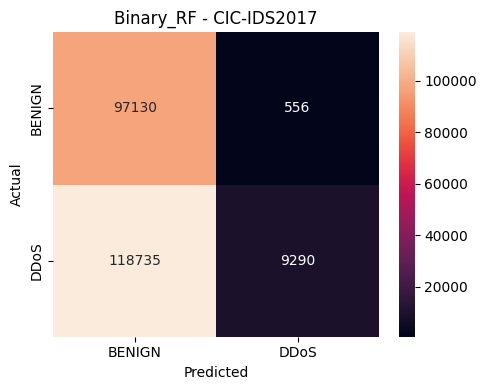


Binary_XGBoost
[[ 97365    321]
 [128024      1]]


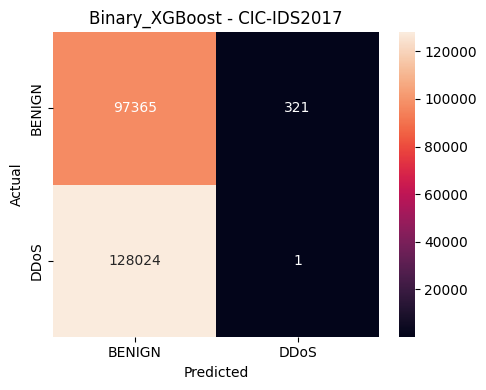


Binary_LightGBM
[[ 96887    799]
 [128024      1]]


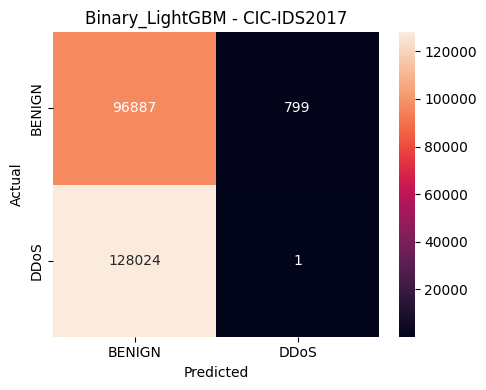

In [83]:

#77 — External Confusion Matrices


from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

for name, results in external_predictions.items():

    cm = confusion_matrix(
        y_2017_final,
        results["pred"]
    )

    print(f"\n{name}")
    print(cm)

    plt.figure(
        figsize=(5,4)
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=[
            "BENIGN",
            "DDoS"
        ],
        yticklabels=[
            "BENIGN",
            "DDoS"
        ]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(
        f"{name} - CIC-IDS2017"
    )

    plt.tight_layout()
    plt.show()

In [84]:

#78 — Internal vs External Generalization Gap


internal = binary_validation_df.rename(
    columns={
        "Accuracy": "Internal_Accuracy",
        "Precision": "Internal_Precision",
        "Recall": "Internal_Recall",
        "F1": "Internal_F1"
    }
).copy()

external = external_results_df.rename(
    columns={
        "Accuracy": "External_Accuracy",
        "Precision": "External_Precision",
        "Recall": "External_Recall",
        "F1": "External_F1",
        "ROC-AUC": "External_ROC-AUC"
    }
).copy()

# binary_validation_df does not currently contain ROC-AUC,
# so calculate it here from the source validation predictions.

internal_auc = []

for name, model in binary_trained.items():

    val_prob = model.predict_proba(
        X_val_sel
    )[:,1]

    internal_auc.append({
        "Model": name,
        "Internal_ROC-AUC":
            roc_auc_score(
                y_val_binary,
                val_prob
            )
    })

internal_auc_df = pd.DataFrame(
    internal_auc
)

internal = internal.merge(
    internal_auc_df,
    on="Model",
    how="left"
)

comparison = internal.merge(
    external,
    on="Model",
    how="inner"
)

comparison["F1_Drop"] = (
    comparison["Internal_F1"]
    - comparison["External_F1"]
)

comparison["Recall_Drop"] = (
    comparison["Internal_Recall"]
    - comparison["External_Recall"]
)

comparison["ROC_AUC_Drop"] = (
    comparison["Internal_ROC-AUC"]
    - comparison["External_ROC-AUC"]
)

comparison["Accuracy_Drop"] = (
    comparison["Internal_Accuracy"]
    - comparison["External_Accuracy"]
)

print("=" *110)
print("CROSS-DATASET GENERALIZATION GAP")
print("=" *110)

print(
    comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

CROSS-DATASET GENERALIZATION GAP
          Model  Internal_Accuracy  Internal_Precision  Internal_Recall  Internal_F1  Internal_ROC-AUC  External_Accuracy  External_Precision  External_Recall  External_F1  External_ROC-AUC  F1_Drop  Recall_Drop  ROC_AUC_Drop  Accuracy_Drop
      Binary_RF           0.999361            0.999809         0.999175     0.999492          0.999996           0.471488            0.943530         0.072564     0.134764          0.766322 0.864728     0.926611      0.233674       0.527873
 Binary_XGBoost           0.999481            0.999682         0.999492     0.999587          0.999993           0.431375            0.003106         0.000008     0.000016          0.476937 0.999572     0.999484      0.523056       0.568106
Binary_LightGBM           0.999640            0.999873         0.999556     0.999714          0.999998           0.429257            0.001250         0.000008     0.000016          0.432760 0.999699     0.999548      0.567238       0.570384


In [85]:

#79 — Feature Distribution Shift


from scipy.stats import ks_2samp

shift_results = []

for feature in TOP_FEATURES_2017:

    train_values = (
        X_train_sel[feature]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    external_values = (
        X_2017_final[feature]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    ks_stat, p_value = ks_2samp(
        train_values,
        external_values
    )

    shift_results.append({

        "Feature": feature,

        "Train_Median":
            train_values.median(),

        "External_Median":
            external_values.median(),

        "Train_Mean":
            train_values.mean(),

        "External_Mean":
            external_values.mean(),

        "KS_Statistic":
            ks_stat,

        "KS_pvalue":
            p_value
    })

shift_df = pd.DataFrame(
    shift_results
).sort_values(
    "KS_Statistic",
    ascending=False
)

print("=" *110)
print("FEATURE DISTRIBUTION SHIFT")
print("=" *110)

print(
    shift_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4g}"
    )
)

FEATURE DISTRIBUTION SHIFT
                 Feature  Train_Median  External_Median  Train_Mean  External_Mean  KS_Statistic  KS_pvalue
       Packet Length Max             6              517       268.8           3227        0.4247          0
      Packet Length Mean             6            110.6       149.3          515.1        0.3933          0
       Packet Length Min             6                0       120.2          8.073         0.375          0
   Fwd Packet Length Min             6                0       120.9          27.89        0.3639          0
         Avg Packet Size             9              141       196.6          574.7        0.3636          0
       Subflow Fwd Bytes            72               30         795          939.6        0.3542          0
Fwd Packets Length Total            72               30         795          939.6        0.3542          0
           Fwd Packets/s         34.63            2.316   1.704e+05      1.262e+04        0.2837          0
 

In [86]:

#80 — Feature Range Comparison


range_results = []

for feature in TOP_FEATURES_2017:

    train_values = (
        X_train_sel[feature]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    external_values = (
        X_2017_final[feature]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    range_results.append({

        "Feature": feature,

        "Train_Min":
            train_values.min(),

        "Train_Max":
            train_values.max(),

        "External_Min":
            external_values.min(),

        "External_Max":
            external_values.max(),

        "Train_Median":
            train_values.median(),

        "External_Median":
            external_values.median()
    })

range_df = pd.DataFrame(
    range_results
)

print(
    range_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4g}"
    )
)

                 Feature  Train_Min  Train_Max  External_Min  External_Max  Train_Median  External_Median
         Avg Packet Size          0       2208             0          2528             9              141
       Subflow Fwd Bytes          0  2.085e+05             0      1.83e+05            72               30
Fwd Packets Length Total          0  2.085e+05             0      1.83e+05            72               30
            Flow Bytes/s          0  2.944e+09      -1.2e+07      2.07e+09          5131             1133
    Avg Fwd Segment Size          0       2131             0          3867             6            8.667
  Fwd Packet Length Mean          0       2131             0          3867             6            8.667
      Packet Length Mean          0       1519             0          1937             6            110.6
       Packet Length Max          0       3625             0     1.168e+04             6              517
       Packet Length Min          0       1472

In [87]:

#81 — Class-Conditional Distribution Shift


train_benign_mask = (
    y_train_binary.values == 0
)

train_attack_mask = (
    y_train_binary.values ==1
)

external_benign_mask = (
    y_2017_final.values == 0
)

external_attack_mask = (
    y_2017_final.values ==1
)

class_shift_results = []

for feature in TOP_FEATURES_2017:

    train_benign = (
        X_train_sel.loc[
            train_benign_mask,
            feature
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    ext_benign = (
        X_2017_final.loc[
            external_benign_mask,
            feature
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    train_attack = (
        X_train_sel.loc[
            train_attack_mask,
            feature
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    ext_attack = (
        X_2017_final.loc[
            external_attack_mask,
            feature
        ]
        .replace(
            [np.inf, -np.inf],
            np.nan
        )
        .dropna()
    )

    benign_ks, _ = ks_2samp(
        train_benign,
        ext_benign
    )

    attack_ks, _ = ks_2samp(
        train_attack,
        ext_attack
    )

    class_shift_results.append({

        "Feature": feature,

        "Benign_KS":
            benign_ks,

        "Attack_KS":
            attack_ks
    })

class_shift_df = pd.DataFrame(
    class_shift_results
)

class_shift_df["Average_KS"] = (
    class_shift_df[
        [
            "Benign_KS",
            "Attack_KS"
        ]
    ].mean(axis=1)
)

class_shift_df = (
    class_shift_df
    .sort_values(
        "Average_KS",
        ascending=False
    )
)

print(
    class_shift_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

                 Feature  Benign_KS  Attack_KS  Average_KS
       Packet Length Max     0.2061     0.6354      0.4207
      Packet Length Mean     0.2069     0.5936      0.4002
       Subflow Fwd Bytes     0.1461     0.6471      0.3966
Fwd Packets Length Total     0.1461     0.6471      0.3966
         Avg Packet Size     0.2345     0.5557      0.3951
   Fwd Packet Length Min     0.0786     0.6321      0.3554
      Init Fwd Win Bytes     0.2439     0.4526      0.3482
       Packet Length Min     0.0475     0.6320      0.3397
           Fwd Packets/s     0.2579     0.3342      0.2960
            Flow IAT Max     0.2525     0.3379      0.2952
           Flow IAT Mean     0.2815     0.2847      0.2831
   Fwd Packet Length Max     0.1812     0.3803      0.2807
          Flow Packets/s     0.2774     0.2838      0.2806
  Fwd Packet Length Mean     0.1801     0.3802      0.2801
    Avg Fwd Segment Size     0.1801     0.3802      0.2801
           Flow Duration     0.2422     0.3006      0.27

In [88]:

#82 — External Predictive Score Distribution


rf_prob = external_predictions[
    "Binary_RF"
]["prob"]

prob_df = pd.DataFrame({

    "Probability":
        rf_prob,

    "Actual":
        y_2017_final.to_numpy()
})

print("=" *80)
print("RANDOM FOREST EXTERNAL PROBABILITY DISTRIBUTION")
print("=" *80)

print("\nBENIGN probability statistics:")

print(
    prob_df.loc[
        prob_df["Actual"] == 0,
        "Probability"
    ].describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

print("\nDDoS probability statistics:")

print(
    prob_df.loc[
        prob_df["Actual"] ==1,
        "Probability"
    ].describe(
        percentiles=[
            0.50,
            0.75,
            0.90,
            0.95,
            0.99
        ]
    )
)

RANDOM FOREST EXTERNAL PROBABILITY DISTRIBUTION

BENIGN probability statistics:
count    97686.000000
mean         0.067544
std          0.089176
min          0.000000
50%          0.043333
75%          0.086667
90%          0.160000
95%          0.203333
99%          0.450000
max          0.970000
Name: Probability, dtype: float64

DDoS probability statistics:
count    128025.000000
mean          0.201707
std           0.176097
min           0.000000
50%           0.163333
75%           0.343333
90%           0.486667
95%           0.523333
99%           0.573333
max           0.820000
Name: Probability, dtype: float64


In [89]:

#83 — Source Validation Threshold


from sklearn.metrics import precision_recall_curve

rf_model = binary_trained[
    "Binary_RF"
]

rf_val_prob = rf_model.predict_proba(
    X_val_sel
)[:,1]

precision, recall, thresholds = (
    precision_recall_curve(
        y_val_binary,
        rf_val_prob
    )
)

f1_scores = (
   2 * precision[:-1] * recall[:-1]
    / (
        precision[:-1]
        + recall[:-1]
        +1e-12
    )
)

best_idx = np.argmax(
    f1_scores
)

source_threshold = (
    thresholds[best_idx]
)

source_val_f1 = (
    f1_scores[best_idx]
)

print("=" *80)
print("SOURCE-DATASET THRESHOLD SELECTION")
print("=" *80)

print(
    f"Selected threshold : "
    f"{source_threshold:.6f}"
)

print(
    f"Validation F1      : "
    f"{source_val_f1:.6f}"
)

print("\nThreshold selected using:")
print("CIC-DDoS2019 validation data ONLY")
print("CIC-IDS2017 labels were NOT used.")

SOURCE-DATASET THRESHOLD SELECTION
Selected threshold : 0.573333
Validation F1      : 0.999524

Threshold selected using:
CIC-DDoS2019 validation data ONLY
CIC-IDS2017 labels were NOT used.


In [90]:

#84 — Apply Frozen Source Threshold to CIC-IDS2017


rf_external_prob = external_predictions[
    "Binary_RF"
]["prob"]

rf_external_pred_frozen = (
    rf_external_prob >= source_threshold
).astype(int)

external_frozen_results = {

    "Accuracy":
        accuracy_score(
            y_2017_final,
            rf_external_pred_frozen
        ),

    "Precision":
        precision_score(
            y_2017_final,
            rf_external_pred_frozen,
            zero_division=0
        ),

    "Recall":
        recall_score(
            y_2017_final,
            rf_external_pred_frozen,
            zero_division=0
        ),

    "F1":
        f1_score(
            y_2017_final,
            rf_external_pred_frozen,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            y_2017_final,
            rf_external_prob
        )
}

print("=" *80)
print("CIC-DDoS2019 → CIC-IDS2017")
print("FROZEN SOURCE-DATASET THRESHOLD")
print("=" *80)

print(
    f"Threshold : {source_threshold:.6f}"
)

for metric, value in external_frozen_results.items():

    print(
        f"{metric:<10}: {value:.6f}"
    )

CIC-DDoS2019 → CIC-IDS2017
FROZEN SOURCE-DATASET THRESHOLD
Threshold : 0.573333
Accuracy  : 0.437179
Precision : 0.773783
Recall    : 0.010928
F1        : 0.021551
ROC-AUC   : 0.766322


In [91]:

#85 — Default vs Frozen Source Threshold


rf_pred_default = (
    rf_external_prob >= 0.50
).astype(int)

threshold_comparison = pd.DataFrame([

    {

        "Evaluation":
            "Default threshold",

        "Threshold":
            0.50,

        "Accuracy":
            accuracy_score(
                y_2017_final,
                rf_pred_default
            ),

        "Precision":
            precision_score(
                y_2017_final,
                rf_pred_default,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_2017_final,
                rf_pred_default,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_2017_final,
                rf_pred_default,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                y_2017_final,
                rf_external_prob
            )
    },

    {

        "Evaluation":
            "Frozen source threshold",

        "Threshold":
            source_threshold,

        "Accuracy":
            accuracy_score(
                y_2017_final,
                rf_external_pred_frozen
            ),

        "Precision":
            precision_score(
                y_2017_final,
                rf_external_pred_frozen,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_2017_final,
                rf_external_pred_frozen,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_2017_final,
                rf_external_pred_frozen,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                y_2017_final,
                rf_external_prob
            )
    }
])

print(
    threshold_comparison.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

             Evaluation  Threshold  Accuracy  Precision   Recall       F1  ROC-AUC
      Default threshold   0.500000  0.471351   0.939679 0.072642 0.134859 0.766322
Frozen source threshold   0.573333  0.437179   0.773783 0.010928 0.021551 0.766322


In [92]:

##86 — Negative Value Check


negative_results = []

for feature in TOP_FEATURES_2017:

    values = X_2017_final[
        feature
    ]

    negative_count = (
        values < 0
    ).sum()

    negative_results.append({

        "Feature": feature,

        "Negative_Count":
            negative_count,

        "Negative_Percentage":
           100
            * negative_count
            / len(values),

        "Minimum":
            values.min()
    })

negative_df = (
    pd.DataFrame(
        negative_results
    )
    .sort_values(
        "Negative_Count",
        ascending=False
    )
)

print(
    negative_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

                 Feature  Negative_Count  Negative_Percentage        Minimum
      Init Fwd Win Bytes           32925              14.5872        -1.0000
            Flow Bytes/s               2               0.0009 -12000000.0000
            Flow IAT Max               2               0.0009        -1.0000
           Flow IAT Mean               2               0.0009        -1.0000
           Flow Duration               2               0.0009        -1.0000
          Flow Packets/s               2               0.0009  -2000000.0000
         Avg Packet Size               0               0.0000         0.0000
       Subflow Fwd Bytes               0               0.0000         0.0000
Fwd Packets Length Total               0               0.0000         0.0000
    Avg Fwd Segment Size               0               0.0000         0.0000
      Packet Length Mean               0               0.0000         0.0000
  Fwd Packet Length Mean               0               0.0000         0.0000

In [93]:

#87 — Check -1 Sentinel Values


sentinel_results = []

for feature in TOP_FEATURES_2017:

    values = X_2017_final[
        feature
    ]

    count_minus_one = (
        values == -1
    ).sum()

    sentinel_results.append({

        "Feature": feature,

        "Minus_1_Count":
            count_minus_one,

        "Percentage":
           100
            * count_minus_one
            / len(values)
    })

sentinel_df = (
    pd.DataFrame(
        sentinel_results
    )
    .sort_values(
        "Minus_1_Count",
        ascending=False
    )
)

print(
    sentinel_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

                 Feature  Minus_1_Count  Percentage
      Init Fwd Win Bytes          32925     14.5872
           Flow Duration              2      0.0009
            Flow IAT Max              2      0.0009
           Flow IAT Mean              2      0.0009
            Flow Bytes/s              0      0.0000
Fwd Packets Length Total              0      0.0000
       Subflow Fwd Bytes              0      0.0000
         Avg Packet Size              0      0.0000
       Packet Length Max              0      0.0000
    Avg Fwd Segment Size              0      0.0000
      Packet Length Mean              0      0.0000
  Fwd Packet Length Mean              0      0.0000
   Fwd Packet Length Max              0      0.0000
   Fwd Packet Length Min              0      0.0000
       Packet Length Min              0      0.0000
          Flow Packets/s              0      0.0000
           Fwd Packets/s              0      0.0000
            Flow IAT Std              0      0.0000
            

In [94]:

#88 — Init Fwd Win Bytes Sentinel Comparison


print("=" *80)
print("INIT FWD WIN BYTES: SENTINEL COMPARISON")
print("=" *80)

train_init_win = X_train_sel[
    "Init Fwd Win Bytes"
]

train_minus_one = (
    train_init_win == -1
).sum()

train_minus_one_pct = (
   100
    * train_minus_one
    / len(train_init_win)
)

external_init_win = X_2017_final[
    "Init Fwd Win Bytes"
]

external_minus_one = (
    external_init_win == -1
).sum()

external_minus_one_pct = (
   100
    * external_minus_one
    / len(external_init_win)
)

print(
    f"CIC-DDoS2019: "
    f"{train_minus_one:,} rows "
    f"({train_minus_one_pct:.4f}%)"
)

print(
    f"CIC-IDS2017:  "
    f"{external_minus_one:,} rows "
    f"({external_minus_one_pct:.4f}%)"
)

INIT FWD WIN BYTES: SENTINEL COMPARISON
CIC-DDoS2019: 36,486 rows (36.4364%)
CIC-IDS2017:  32,925 rows (14.5872%)


In [95]:

#89 — Sentinel Rate by Class


train_check = pd.DataFrame({

    "Label":
        y_train_binary.to_numpy(),

    "Init_Fwd_Win":
        X_train_sel[
            "Init Fwd Win Bytes"
        ].to_numpy()
})

external_check = pd.DataFrame({

    "Label":
        y_2017_final.to_numpy(),

    "Init_Fwd_Win":
        X_2017_final[
            "Init Fwd Win Bytes"
        ].to_numpy()
})

print("=" *80)
print("CIC-DDoS2019 -1 RATE BY CLASS")
print("=" *80)

print(
    train_check
    .groupby("Label")["Init_Fwd_Win"]
    .apply(
        lambda x:
        (x == -1).mean() *100
    )
)

print("\n" + "=" *80)
print("CIC-IDS2017 -1 RATE BY CLASS")
print("=" *80)

print(
    external_check
    .groupby("Label")["Init_Fwd_Win"]
    .apply(
        lambda x:
        (x == -1).mean() *100
    )
)

CIC-DDoS2019 -1 RATE BY CLASS
Label
0    33.956168
1    37.898848
Name: Init_Fwd_Win, dtype: float64

CIC-IDS2017 -1 RATE BY CLASS
Label
0    33.704932
1     0.000000
Name: Init_Fwd_Win, dtype: float64


In [96]:

#90 — Sensitivity: Remove Init Fwd Win Bytes


sensitivity_features = [
    f
    for f in TOP_FEATURES_2017
    if f != "Init Fwd Win Bytes"
]

print(
    "Original feature count:",
    len(TOP_FEATURES_2017)
)

print(
    "Sensitivity feature count:",
    len(sensitivity_features)
)

print(
    "Removed feature:",
    "Init Fwd Win Bytes"
)

X_train_sens = X_train_sel[
    sensitivity_features
].copy()

X_external_sens = X_2017_final[
    sensitivity_features
].copy()

rf_sensitivity = RandomForestClassifier(
    n_estimators=300,
    random_state=SEED,
    n_jobs=-1,
    class_weight="balanced"
)

rf_sensitivity.fit(
    X_train_sens,
    y_train_binary
)

sens_pred = rf_sensitivity.predict(
    X_external_sens
)

sens_prob = rf_sensitivity.predict_proba(
    X_external_sens
)[:,1]

sens_results = {

    "Accuracy":
        accuracy_score(
            y_2017_final,
            sens_pred
        ),

    "Precision":
        precision_score(
            y_2017_final,
            sens_pred,
            zero_division=0
        ),

    "Recall":
        recall_score(
            y_2017_final,
            sens_pred,
            zero_division=0
        ),

    "F1":
        f1_score(
            y_2017_final,
            sens_pred,
            zero_division=0
        ),

    "ROC-AUC":
        roc_auc_score(
            y_2017_final,
            sens_prob
        )
}

print("\n" + "=" *80)
print(
    "SENSITIVITY: RF WITHOUT INIT FWD WIN BYTES"
)
print("=" *80)

for metric, value in sens_results.items():

    print(
        f"{metric:<12}: {value:.6f}"
    )

Original feature count: 20
Sensitivity feature count: 19
Removed feature: Init Fwd Win Bytes

SENSITIVITY: RF WITHOUT INIT FWD WIN BYTES
Accuracy    : 0.630067
Precision   : 0.961143
Recall      : 0.362453
F1          : 0.526398
ROC-AUC     : 0.802910


In [97]:

#91 — One-Feature-Removal External Sensitivity


loo_results = []

for removed_feature in TOP_FEATURES_2017:

    features_loo = [
        f
        for f in TOP_FEATURES_2017
        if f != removed_feature
    ]

    X_train_loo = X_train_sel[
        features_loo
    ]

    X_external_loo = X_2017_final[
        features_loo
    ]

    model_loo = RandomForestClassifier(
        n_estimators=300,
        random_state=SEED,
        n_jobs=-1,
        class_weight="balanced"
    )

    model_loo.fit(
        X_train_loo,
        y_train_binary
    )

    pred_loo = model_loo.predict(
        X_external_loo
    )

    prob_loo = model_loo.predict_proba(
        X_external_loo
    )[:,1]

    loo_results.append({

        "Removed_Feature":
            removed_feature,

        "Accuracy":
            accuracy_score(
                y_2017_final,
                pred_loo
            ),

        "Precision":
            precision_score(
                y_2017_final,
                pred_loo,
                zero_division=0
            ),

        "Recall":
            recall_score(
                y_2017_final,
                pred_loo,
                zero_division=0
            ),

        "F1":
            f1_score(
                y_2017_final,
                pred_loo,
                zero_division=0
            ),

        "ROC-AUC":
            roc_auc_score(
                y_2017_final,
                prob_loo
            )
    })

loo_df = (
    pd.DataFrame(
        loo_results
    )
    .sort_values(
        "ROC-AUC",
        ascending=False
    )
)

print("=" *110)
print("ONE-FEATURE-REMOVAL EXTERNAL SENSITIVITY")
print("=" *110)

print(
    loo_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)

ONE-FEATURE-REMOVAL EXTERNAL SENSITIVITY
         Removed_Feature  Accuracy  Precision  Recall     F1  ROC-AUC
         Avg Packet Size    0.4516     0.8906  0.0377 0.0723   0.8459
      Init Fwd Win Bytes    0.6301     0.9611  0.3625 0.5264   0.8029
           Flow IAT Mean    0.4534     0.8746  0.0425 0.0810   0.7537
          Flow Packets/s    0.4351     0.6351  0.0097 0.0190   0.7523
            Flow IAT Std    0.4505     0.8600  0.0374 0.0717   0.7481
            Flow Bytes/s    0.4347     0.6041  0.0099 0.0194   0.7400
             Fwd IAT Max    0.4649     0.9071  0.0631 0.1180   0.7287
           Flow Duration    0.4652     0.9119  0.0633 0.1184   0.7257
   Fwd Packet Length Min    0.4666     0.9391  0.0637 0.1193   0.7176
           Fwd IAT Total    0.4686     0.9201  0.0691 0.1285   0.7172
            Flow IAT Max    0.4531     0.8737  0.0419 0.0799   0.7161
Fwd Packets Length Total    0.4403     0.8073  0.0173 0.0339   0.7150
       Subflow Fwd Bytes    0.4403     0.8073  0.

In [98]:

#92 — Save CIC-IDS2017 Cross-Dataset Results


external_results_df.to_csv(
    f"{RESULTS_DIR}/cross_dataset_CIC2019_to_CIC2017.csv",
    index=False
)

comparison.to_csv(
    f"{RESULTS_DIR}/cross_dataset_generalization_gap.csv",
    index=False
)

shift_df.to_csv(
    f"{RESULTS_DIR}/CIC2017_feature_distribution_shift.csv",
    index=False
)

range_df.to_csv(
    f"{RESULTS_DIR}/CIC2017_feature_range_comparison.csv",
    index=False
)

class_shift_df.to_csv(
    f"{RESULTS_DIR}/CIC2017_class_conditional_shift.csv",
    index=False
)

threshold_comparison.to_csv(
    f"{RESULTS_DIR}/CIC2017_threshold_transfer.csv",
    index=False
)

sentinel_df.to_csv(
    f"{RESULTS_DIR}/CIC2017_sentinel_analysis.csv",
    index=False
)

loo_df.to_csv(
    f"{RESULTS_DIR}/CIC2017_feature_loo_sensitivity.csv",
    index=False
)

print(
    "CIC-IDS2017 cross-dataset results saved."
)

CIC-IDS2017 cross-dataset results saved.


In [99]:
#93 — Load CSE-CIC-IDS2018 (Second External Dataset)


import pandas as pd
import numpy as np
import os

IDS2018_PATH = os.path.join("Datasets", "dataset2018",
                             "DDoS1-Tuesday-20-02-2018_TrafficForML_CICFlowMeter.parquet")

if not os.path.exists(IDS2018_PATH):
    raise FileNotFoundError(f"Dataset not found:\n{IDS2018_PATH}")

df_2018 = pd.read_parquet(IDS2018_PATH)
df_2018.columns = df_2018.columns.str.strip()

print("CSE-CIC-IDS2018 (DDoS1) shape:", df_2018.shape)

label_col_2018 = [c for c in df_2018.columns if 'label' in c.lower()][0]
print("Label column:", label_col_2018)
print("\nLabel distribution:")
print(df_2018[label_col_2018].value_counts())

CSE-CIC-IDS2018 (DDoS1) shape: (954846, 78)
Label column: Label

Label distribution:
Label
DDoS attacks-LOIC-HTTP    575364
Benign                    379482
Name: count, dtype: int64


In [100]:
#94 — CIC-DDoS2019 → CSE-CIC-IDS2018 Feature Mapping (verified)

FEATURE_MAPPING_2018 = {
    "Avg Packet Size":              "Avg Packet Size",
    "Subflow Fwd Bytes":            "Subflow Fwd Bytes",
    "Fwd Packets Length Total":     "Fwd Packets Length Total",
    "Flow Bytes/s":                 "Flow Bytes/s",
    "Avg Fwd Segment Size":         "Avg Fwd Segment Size",
    "Fwd Packet Length Mean":       "Fwd Packet Length Mean",
    "Packet Length Mean":           "Packet Length Mean",
    "Packet Length Max":            "Packet Length Max",
    "Packet Length Min":            "Packet Length Min",
    "Fwd Packet Length Min":        "Fwd Packet Length Min",
    "Fwd Packet Length Max":        "Fwd Packet Length Max",
    "Flow IAT Max":                 "Flow IAT Max",
    "Flow IAT Mean":                "Flow IAT Mean",
    "Flow Duration":                "Flow Duration",
    "Flow Packets/s":               "Flow Packets/s",
    "Fwd Packets/s":                "Fwd Packets/s",
    "Flow IAT Std":                 "Flow IAT Std",
    "Fwd IAT Max":                  "Fwd IAT Max",
    "Init Fwd Win Bytes":           "Init Fwd Win Bytes",
    "Fwd IAT Total":                "Fwd IAT Total"
}

resolved_mapping_2018 = {}
missing_2018 = []

for f in TOP_FEATURES_2017:
    target = FEATURE_MAPPING_2018[f]
    if target in df_2018.columns:
        resolved_mapping_2018[f] = target
    else:
        missing_2018.append((f, target))

print("Feature mapping check (2018):\n")
for feature in TOP_FEATURES_2017:
    resolved = resolved_mapping_2018.get(feature, "✗ NOT FOUND")
    print(f"{feature:<32} -> {resolved}")

if missing_2018:
    raise ValueError(
        "Missing CSE-CIC-IDS2018 features:\n" +
        "\n".join(f"{f} -> {t}" for f, t in missing_2018)
    )

print("\n✓ ALL 20 FEATURES AVAILABLE")

Feature mapping check (2018):

Avg Packet Size                  -> Avg Packet Size
Subflow Fwd Bytes                -> Subflow Fwd Bytes
Fwd Packets Length Total         -> Fwd Packets Length Total
Flow Bytes/s                     -> Flow Bytes/s
Avg Fwd Segment Size             -> Avg Fwd Segment Size
Fwd Packet Length Mean           -> Fwd Packet Length Mean
Packet Length Mean               -> Packet Length Mean
Packet Length Max                -> Packet Length Max
Packet Length Min                -> Packet Length Min
Fwd Packet Length Min            -> Fwd Packet Length Min
Fwd Packet Length Max            -> Fwd Packet Length Max
Flow IAT Max                     -> Flow IAT Max
Flow IAT Mean                    -> Flow IAT Mean
Flow Duration                    -> Flow Duration
Flow Packets/s                   -> Flow Packets/s
Fwd Packets/s                    -> Fwd Packets/s
Flow IAT Std                     -> Flow IAT Std
Fwd IAT Max                      -> Fwd IAT Max
Init Fwd Wi

In [101]:
#95 — Build + Clean CSE-CIC-IDS2018 External Feature Matrix

X_2018 = df_2018[[resolved_mapping_2018[f] for f in TOP_FEATURES_2017]].copy()
X_2018.columns = TOP_FEATURES_2017

X_2018 = X_2018.apply(pd.to_numeric, errors="coerce")
X_2018 = X_2018.replace([np.inf, -np.inf], np.nan)

invalid_mask_2018 = X_2018.isna().any(axis=1)
print("Rows before cleaning:", len(X_2018))
print("Rows with NaN/Inf:", invalid_mask_2018.sum())

X_2018_clean = X_2018.loc[~invalid_mask_2018].copy()

labels_2018 = (
    df_2018.loc[X_2018_clean.index, label_col_2018]
    .astype(str).str.strip()
)
labels_2018_norm = labels_2018.apply(
    lambda x: x.replace('DrDoS_', '').replace('DDoS-', '')
)

print("\nExternal 2018 classes found:", sorted(labels_2018_norm.unique()))

y_2018_final = (labels_2018_norm.str.upper() != "BENIGN").astype(int)

X_2018_final = X_2018_clean[TOP_FEATURES_2017].copy()
y_2018_final = y_2018_final.loc[X_2018_final.index].astype(int)

print("\nCSE-CIC-IDS2018 (DDoS1) external test set:", X_2018_final.shape)
print(y_2018_final.value_counts())
print("\nNaN:", X_2018_final.isna().sum().sum())
print("Inf:", np.isinf(X_2018_final.to_numpy()).sum())
print("\n✓ External test set ready.")

Rows before cleaning: 954846
Rows with NaN/Inf: 0

External 2018 classes found: ['Benign', 'DDoS attacks-LOIC-HTTP']

CSE-CIC-IDS2018 (DDoS1) external test set: (954846, 20)
Label
1    575364
0    379482
Name: count, dtype: int64

NaN: 0
Inf: 0

✓ External test set ready.


In [102]:
# #96 — CROSS-DATASET GENERALIZATION: CIC-DDoS2019 → CSE-CIC-IDS2018
# ============================================================

external_2018_results = []
external_2018_predictions = {}

for name, model in binary_trained.items():
    print(f"Evaluating {name}...")

    pred = model.predict(X_2018_final)
    prob = model.predict_proba(X_2018_final)[:, 1]

    external_2018_predictions[name] = {"pred": pred, "prob": prob}

    external_2018_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_2018_final, pred),
        "Precision": precision_score(y_2018_final, pred, zero_division=0),
        "Recall": recall_score(y_2018_final, pred, zero_division=0),
        "F1": f1_score(y_2018_final, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_2018_final, prob)
    })

external_2018_results_df = pd.DataFrame(external_2018_results)

print("\n" + "=" * 90)
print("CROSS-DATASET VALIDATION RESULTS — CIC-DDoS2019 → CSE-CIC-IDS2018 (DDoS1)")
print("=" * 90)
print(external_2018_results_df.sort_values("F1", ascending=False)
      .to_string(index=False, float_format=lambda x: f"{x:.6f}"))

external_2018_results_df.to_csv(
    f"{RESULTS_DIR}/cross_dataset_CIC2019_to_CIC2018.csv", index=False
)

Evaluating Binary_RF...
Evaluating Binary_XGBoost...
Evaluating Binary_LightGBM...

CROSS-DATASET VALIDATION RESULTS — CIC-DDoS2019 → CSE-CIC-IDS2018 (DDoS1)
          Model  Accuracy  Precision   Recall       F1  ROC-AUC
      Binary_RF  0.565616   0.990951 0.281690 0.438679 0.838907
 Binary_XGBoost  0.404464   0.897621 0.013181 0.025981 0.680510
Binary_LightGBM  0.403446   0.814353 0.012938 0.025471 0.888508


In [103]:
# #97 — Repeated-Seed Evaluation Across Both External Datasets

external_seed_results = []

for seed in REPEAT_SEEDS:

    rf_seed = RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        n_jobs=-1, random_state=seed
    )
    rf_seed.fit(X_train_sel, y_train_binary)

    for ext_name, X_ext, y_ext in [
        ("CIC-IDS2017", X_2017_final, y_2017_final),
        ("CSE-CIC-IDS2018", X_2018_final, y_2018_final),
    ]:
        pred = rf_seed.predict(X_ext)
        prob = rf_seed.predict_proba(X_ext)[:, 1]

        external_seed_results.append({
            "Seed": seed,
            "External_Dataset": ext_name,
            "Accuracy": accuracy_score(y_ext, pred),
            "Precision": precision_score(y_ext, pred, zero_division=0),
            "Recall": recall_score(y_ext, pred, zero_division=0),
            "F1": f1_score(y_ext, pred, zero_division=0),
            "ROC-AUC": roc_auc_score(y_ext, prob)
        })

external_seed_df = pd.DataFrame(external_seed_results)
print(external_seed_df)

print("\nMean ± SD by external dataset:")
print(
    external_seed_df
    .groupby("External_Dataset")[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
    .agg(["mean", "std"])
)

external_seed_df.to_csv(f"{RESULTS_DIR}/repeated_cross_dataset_runs.csv", index=False)

   Seed External_Dataset  Accuracy  Precision    Recall        F1   ROC-AUC
0    42      CIC-IDS2017  0.471488   0.943530  0.072564  0.134764  0.766322
1    42  CSE-CIC-IDS2018  0.565616   0.990951  0.281690  0.438679  0.838907
2    52      CIC-IDS2017  0.470119   0.918280  0.072236  0.133936  0.740562
3    52  CSE-CIC-IDS2018  0.609177   0.934118  0.378074  0.538283  0.811569
4    62      CIC-IDS2017  0.458573   0.887365  0.052060  0.098350  0.669805
5    62  CSE-CIC-IDS2018  0.542762   0.990166  0.243609  0.391017  0.828545
6    72      CIC-IDS2017  0.451919   0.863690  0.040039  0.076530  0.755304
7    72  CSE-CIC-IDS2018  0.581837   0.992741  0.308292  0.470478  0.767897
8    82      CIC-IDS2017  0.493614   0.961911  0.111650  0.200077  0.781635
9    82  CSE-CIC-IDS2018  0.606595   0.932037  0.374427  0.534236  0.794977

Mean ± SD by external dataset:
                  Accuracy           Precision              Recall            \
                      mean       std      mean      

In [104]:
# #98 — Repeated-Seed Hybrid Confidence Threshold Selection

hybrid_seed_results = []

for seed in REPEAT_SEEDS:

    rf_seed = RandomForestClassifier(
        n_estimators=300, class_weight="balanced",
        n_jobs=-1, random_state=seed
    )
    rf_seed.fit(X_train_sel, y_train_multi)

    iso_seed = IsolationForest(
        n_estimators=300, contamination="auto",
        n_jobs=-1, random_state=seed
    )
    iso_seed.fit(X_train_benign)

    val_scores_seed = iso_seed.decision_function(X_val_sel)
    val_benign_seed = val_scores_seed[y_val_binary.values == 0]
    iso_threshold_seed = np.quantile(val_benign_seed, 0.05)

    best_f1, best_conf = -1, None
    for conf in [0.50, 0.60, 0.70, 0.80, 0.90, 0.95]:
        preds = hybrid_predict(
            val_scores_seed, rf_seed, X_val_sel,
            iso_threshold_seed, conf
        )
        bin_pred = (preds != "Benign").astype(int)
        f1 = f1_score(y_val_binary, bin_pred, zero_division=0)
        if f1 > best_f1:
            best_f1, best_conf = f1, conf

    hybrid_seed_results.append({
        "Seed": seed,
        "ISO_Threshold": iso_threshold_seed,
        "Best_Confidence": best_conf,
        "Validation_F1": best_f1
    })

hybrid_seed_df = pd.DataFrame(hybrid_seed_results)
print(hybrid_seed_df)
print("\nBest_Confidence mode/spread:", hybrid_seed_df["Best_Confidence"].describe())

hybrid_seed_df.to_csv(f"{RESULTS_DIR}/repeated_hybrid_threshold_runs.csv", index=False)

   Seed  ISO_Threshold  Best_Confidence  Validation_F1
0    42      -0.083783              0.5       0.302818
1    52      -0.070426              0.5       0.545933
2    62      -0.081980              0.5       0.542973
3    72      -0.077947              0.5       0.299611
4    82      -0.078287              0.5       0.308651

Best_Confidence mode/spread: count    5.0
mean     0.5
std      0.0
min      0.5
25%      0.5
50%      0.5
75%      0.5
max      0.5
Name: Best_Confidence, dtype: float64


In [105]:
import shap, xgboost
print("shap:", shap.__version__)
print("xgboost:", xgboost.__version__)

shap: 0.49.1
xgboost: 3.2.0


In [106]:
pip install -U shap

Note: you may need to restart the kernel to use updated packages.


Computing SHAP for Binary_RF on CIC-IDS2017...


C:\Users\Atharva\AppData\Local\Temp\ipykernel_132564\1229053856.py:92: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_ext, X_shap_ext,


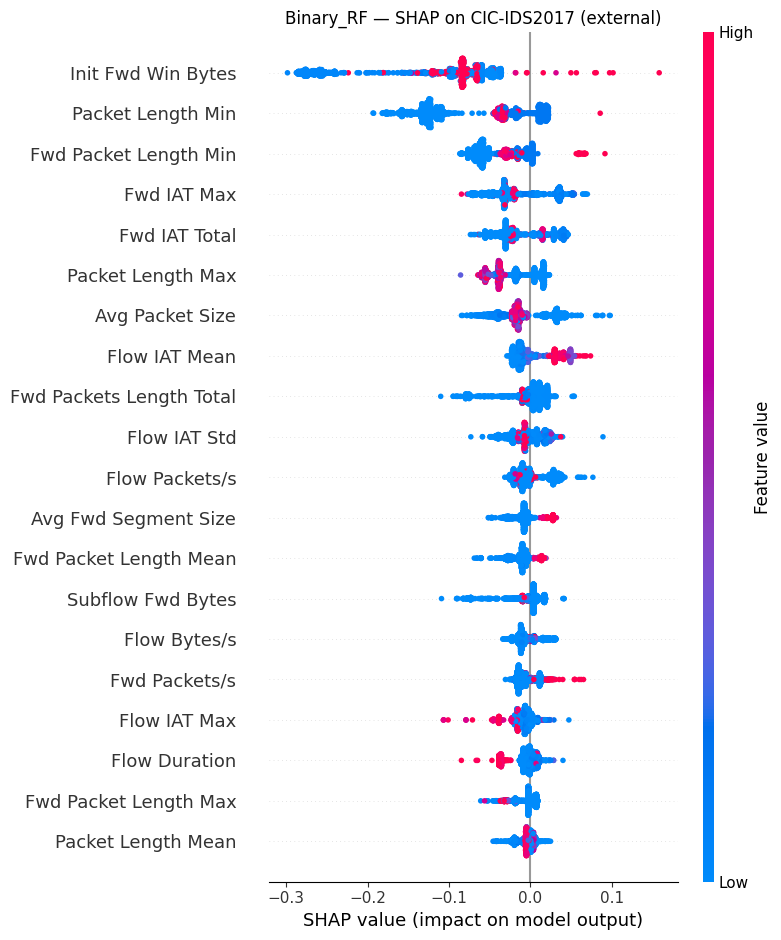

Computing SHAP for Binary_RF on CSE-CIC-IDS2018...


C:\Users\Atharva\AppData\Local\Temp\ipykernel_132564\1229053856.py:92: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_ext, X_shap_ext,


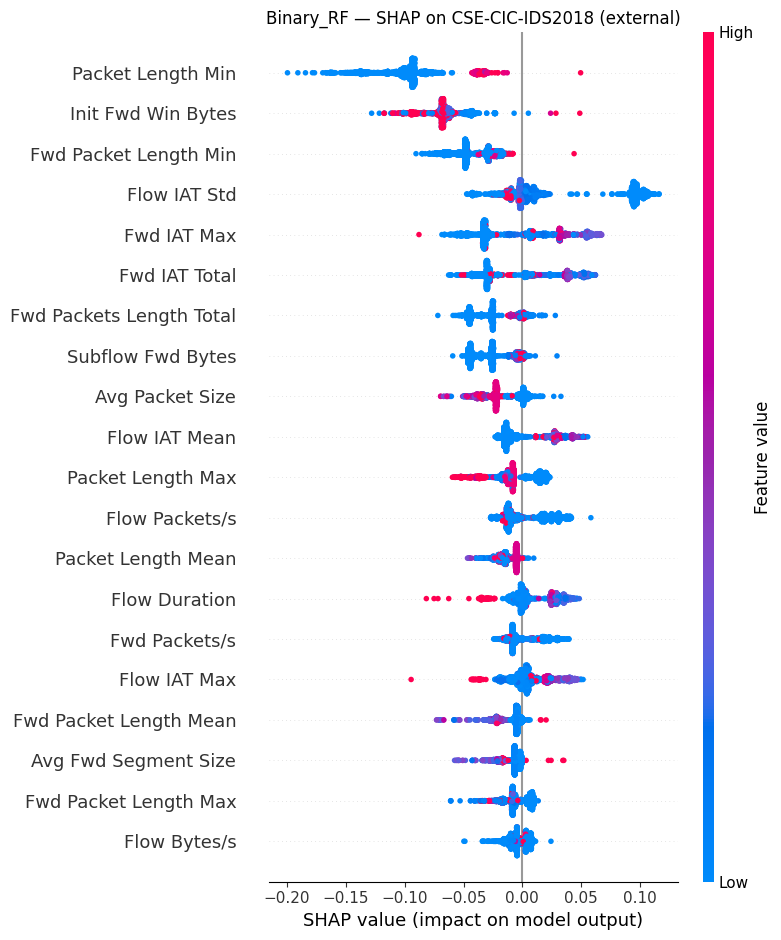

Computing SHAP for Binary_XGBoost on CIC-IDS2017...


C:\Users\Atharva\AppData\Local\Temp\ipykernel_132564\1229053856.py:92: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_ext, X_shap_ext,


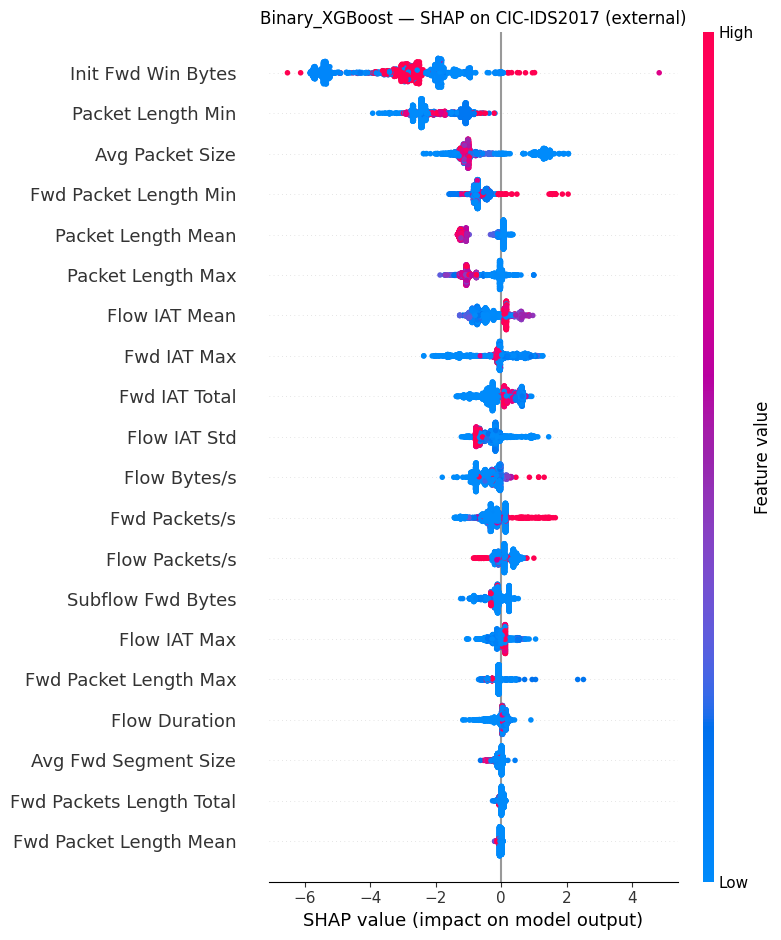

Computing SHAP for Binary_XGBoost on CSE-CIC-IDS2018...


C:\Users\Atharva\AppData\Local\Temp\ipykernel_132564\1229053856.py:92: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_ext, X_shap_ext,


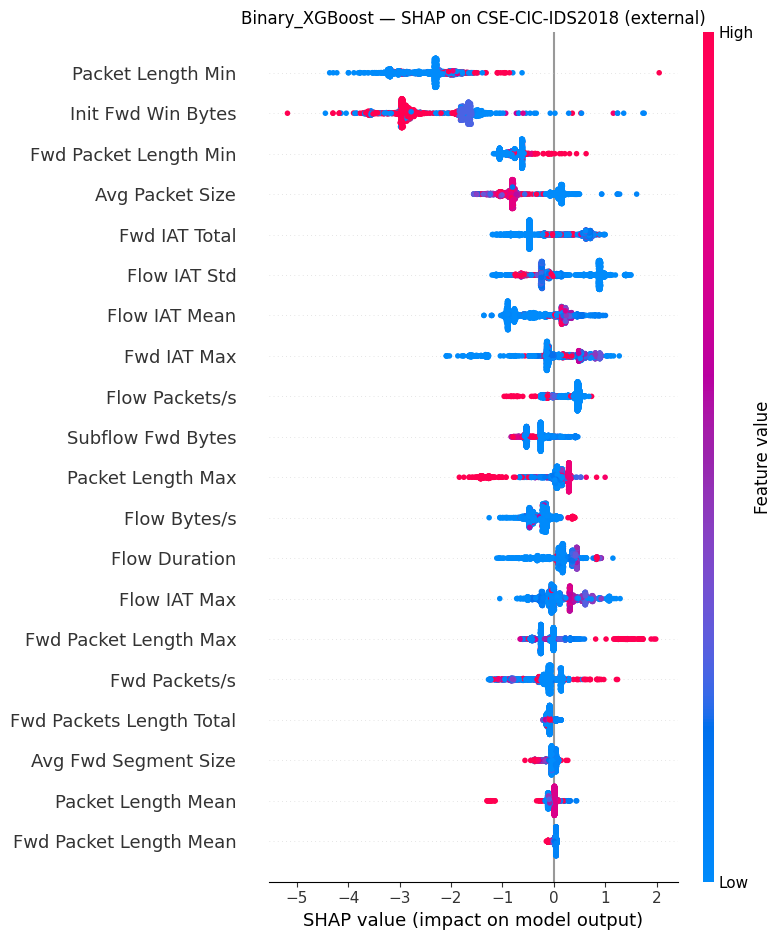

d:\CN Paper\.venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(


Computing SHAP for Binary_LightGBM on CIC-IDS2017...


d:\CN Paper\.venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
C:\Users\Atharva\AppData\Local\Temp\ipykernel_132564\1229053856.py:92: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_ext, X_shap_ext,


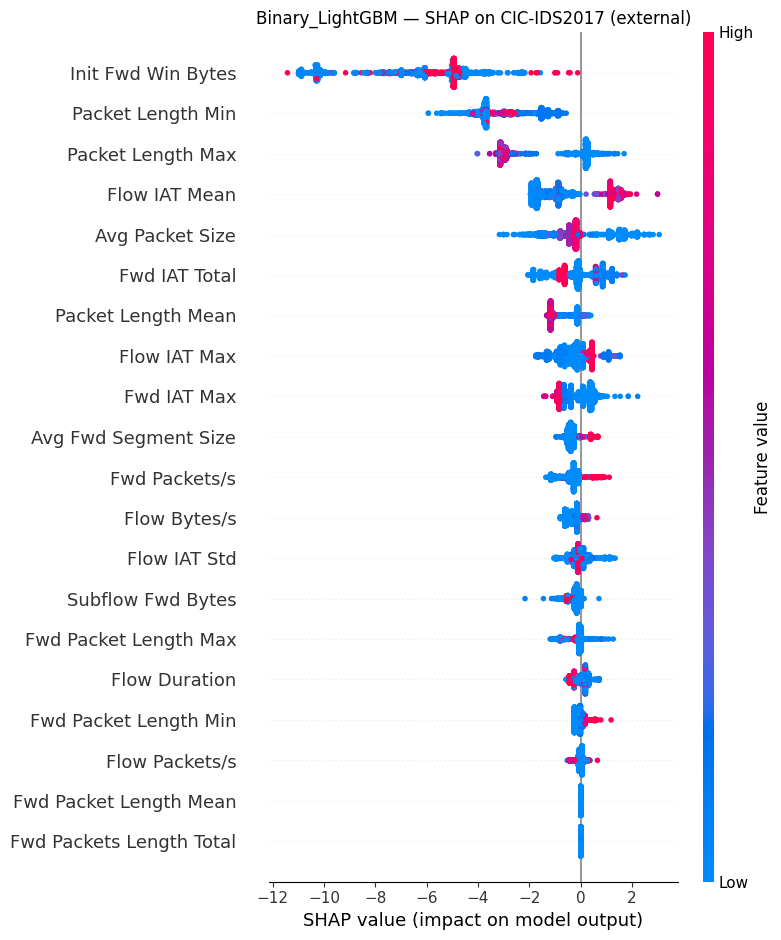

Computing SHAP for Binary_LightGBM on CSE-CIC-IDS2018...


d:\CN Paper\.venv\lib\site-packages\shap\explainers\_tree.py:586: UserWarning: LightGBM binary classifier with TreeExplainer shap values output has changed to a list of ndarray
  warnings.warn(
C:\Users\Atharva\AppData\Local\Temp\ipykernel_132564\1229053856.py:92: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_vals_ext, X_shap_ext,


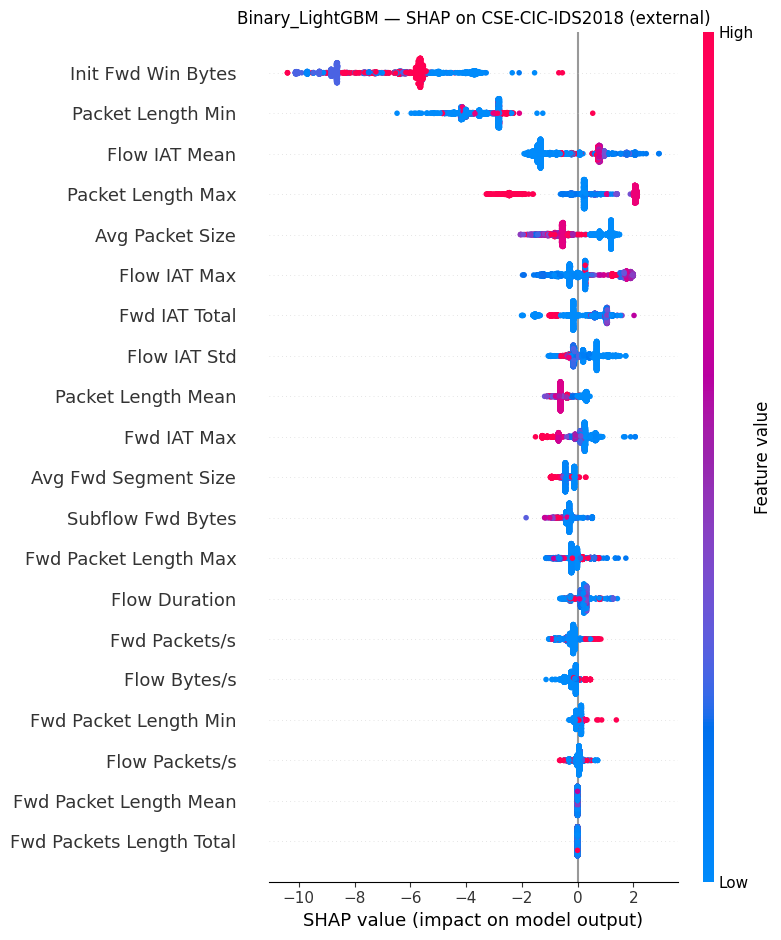

              Model External_Dataset                Feature  \
98  Binary_LightGBM      CIC-IDS2017     Init Fwd Win Bytes   
87  Binary_LightGBM      CIC-IDS2017      Packet Length Max   
97  Binary_LightGBM      CIC-IDS2017            Fwd IAT Max   
86  Binary_LightGBM      CIC-IDS2017     Packet Length Mean   
83  Binary_LightGBM      CIC-IDS2017           Flow Bytes/s   
..              ...              ...                    ...   
79   Binary_XGBoost  CSE-CIC-IDS2018          Fwd IAT Total   
69   Binary_XGBoost  CSE-CIC-IDS2018  Fwd Packet Length Min   
75   Binary_XGBoost  CSE-CIC-IDS2018          Fwd Packets/s   
77   Binary_XGBoost  CSE-CIC-IDS2018            Fwd IAT Max   
68   Binary_XGBoost  CSE-CIC-IDS2018      Packet Length Min   

    Internal_MeanAbsSHAP  External_MeanAbsSHAP     Shift  
98              4.125051              6.494798  2.369747  
87              0.477163              1.581191  1.104028  
97              0.252751              0.451074  0.198322  
86     

In [107]:
# ============================================================
# #99 — SHAP on the Cross-Dataset Failure (both external datasets)
# FIX: normalize RF's 3D binary-class SHAP output to 2D (positive class)
# ============================================================

import shap
import shap.explainers._tree as _shap_tree_mod
import matplotlib.pyplot as plt

if not getattr(_shap_tree_mod, "_base_score_patch_applied", False):
    _orig_decode_ubjson_buffer = _shap_tree_mod.decode_ubjson_buffer

    def _patched_decode_ubjson_buffer(fd):
        jmodel = _orig_decode_ubjson_buffer(fd)
        try:
            lmp = jmodel["learner"]["learner_model_param"]
            bs = lmp.get("base_score")
            if isinstance(bs, str):
                lmp["base_score"] = bs.strip().lstrip("[").rstrip("]")
        except (KeyError, TypeError):
            pass
        return jmodel

    _shap_tree_mod.decode_ubjson_buffer = _patched_decode_ubjson_buffer
    _shap_tree_mod._base_score_patch_applied = True


def get_shap_explainer(name, model):
    if name.startswith("Binary_XGBoost") or name == "XGBoost":
        return shap.TreeExplainer(model.get_booster())
    else:
        return shap.TreeExplainer(model)


def normalize_shap_values(shap_vals):
    """
    Normalize TreeExplainer output to a single 2D (n_samples, n_features)
    array representing the POSITIVE class, regardless of whether the
    underlying model returned a list of per-class arrays (older SHAP
    convention) or a 3D array (n_samples, n_features, n_classes) — which
    is what RandomForestClassifier binary output does in SHAP 0.49.1.
    """
    if isinstance(shap_vals, list):
        return shap_vals[1] if len(shap_vals) > 1 else shap_vals[0]
    if isinstance(shap_vals, np.ndarray) and shap_vals.ndim == 3:
        return shap_vals[:, :, 1]
    return shap_vals


SHAP_INT_SAMPLE = min(2000, len(X_test_known_sel))
X_shap_int = X_test_known_sel.sample(SHAP_INT_SAMPLE, random_state=SEED)

external_datasets = {
    "CIC-IDS2017": X_2017_final,
    "CSE-CIC-IDS2018": X_2018_final
}

shap_external = {}
shap_shift_results = []

for name in ["Binary_RF", "Binary_XGBoost", "Binary_LightGBM"]:
    model = binary_trained[name]
    shap_external[name] = {}

    explainer = get_shap_explainer(name, model)

    shap_vals_int = normalize_shap_values(explainer.shap_values(X_shap_int))
    mean_abs_int = np.abs(shap_vals_int).mean(axis=0)

    for ext_name, X_ext in external_datasets.items():
        print(f"Computing SHAP for {name} on {ext_name}...")

        SHAP_EXT_SAMPLE = min(2000, len(X_ext))
        X_shap_ext = X_ext.sample(SHAP_EXT_SAMPLE, random_state=SEED)

        shap_vals_ext = normalize_shap_values(explainer.shap_values(X_shap_ext))
        shap_external[name][ext_name] = shap_vals_ext

        mean_abs_ext = np.abs(shap_vals_ext).mean(axis=0)

        for feat, int_val, ext_val in zip(TOP_FEATURES_2017, mean_abs_int, mean_abs_ext):
            shap_shift_results.append({
                "Model": name,
                "External_Dataset": ext_name,
                "Feature": feat,
                "Internal_MeanAbsSHAP": float(int_val),
                "External_MeanAbsSHAP": float(ext_val),
                "Shift": float(ext_val) - float(int_val)
            })

        plt.figure()
        shap.summary_plot(shap_vals_ext, X_shap_ext,
                           feature_names=X_shap_ext.columns, show=False)
        plt.title(f"{name} — SHAP on {ext_name} (external)")
        plt.tight_layout()
        plt.savefig(f"{RESULTS_DIR}/shap_external_{name}_{ext_name.replace(' ', '_')}.png")
        plt.show()

shap_shift_df = pd.DataFrame(shap_shift_results)
print(shap_shift_df.sort_values(["Model", "External_Dataset", "Shift"],
                                  ascending=[True, True, False]))

shap_shift_df.to_csv(f"{RESULTS_DIR}/shap_internal_vs_external_shift.csv", index=False)

In [108]:
# NEW CELL (after 99) — Repeated-seed XGBoost / LightGBM on both external datasets
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

def make_models(seed):
    return {
        "Binary_XGBoost": XGBClassifier(
            n_estimators=300, max_depth=8, learning_rate=0.1,
            subsample=0.8, colsample_bytree=0.8,
            objective='binary:logistic', eval_metric='logloss',
            tree_method='hist', n_jobs=-1, random_state=seed),
        # exactly as cell 23 (no bagging -> seed has ~no effect)
        "Binary_LightGBM": LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31,
            class_weight='balanced', n_jobs=-1, random_state=seed, verbosity=-1),
        # seed-sensitive variant (bagging enabled)
        "Binary_LightGBM_bagged": LGBMClassifier(
            n_estimators=300, learning_rate=0.05, num_leaves=31,
            class_weight='balanced', subsample=0.8, subsample_freq=1,
            colsample_bytree=0.8, n_jobs=-1, random_state=seed, verbosity=-1),
    }

boost_rows = []
for seed in REPEAT_SEEDS:
    for mname, m in make_models(seed).items():
        m.fit(X_train_sel, y_train_binary)
        for ext_name, X_ext, y_ext in [
            ("CIC-IDS2017", X_2017_final, y_2017_final),
            ("CSE-CIC-IDS2018", X_2018_final, y_2018_final),
        ]:
            pred = m.predict(X_ext)
            prob = m.predict_proba(X_ext)[:, 1]
            boost_rows.append({
                "Model": mname, "Seed": seed, "External_Dataset": ext_name,
                "Accuracy": accuracy_score(y_ext, pred),
                "Precision": precision_score(y_ext, pred, zero_division=0),
                "Recall": recall_score(y_ext, pred, zero_division=0),
                "F1": f1_score(y_ext, pred, zero_division=0),
                "ROC-AUC": roc_auc_score(y_ext, prob),
            })

all_seed_df = pd.concat(
    [external_seed_df.assign(Model="Binary_RF"), pd.DataFrame(boost_rows)],
    ignore_index=True
)
print(
    all_seed_df.groupby(["Model", "External_Dataset"])
    [["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]]
    .agg(["mean", "std"]).round(4)
)
all_seed_df.to_csv(f"{RESULTS_DIR}/repeated_cross_dataset_runs_all_models.csv", index=False)

                                        Accuracy         Precision          \
                                            mean     std      mean     std   
Model                  External_Dataset                                      
Binary_LightGBM        CIC-IDS2017        0.4293  0.0000    0.0012  0.0000   
                       CSE-CIC-IDS2018    0.4034  0.0000    0.8144  0.0000   
Binary_LightGBM_bagged CIC-IDS2017        0.4311  0.0006    0.0000  0.0000   
                       CSE-CIC-IDS2018    0.3986  0.0023    0.5283  0.3082   
Binary_RF              CIC-IDS2017        0.4691  0.0159    0.9150  0.0401   
                       CSE-CIC-IDS2018    0.5812  0.0281    0.9680  0.0319   
Binary_XGBoost         CIC-IDS2017        0.4316  0.0002    0.0029  0.0017   
                       CSE-CIC-IDS2018    0.4075  0.0112    0.8741  0.0810   

                                         Recall              F1          \
                                           mean     std    mean   

In [109]:
# #100 — Standalone Binary Classifier: Per-Attack Zero-Day Breakdown

binary_zero_day_results = []

for name, model in binary_trained.items():

    pred_zeroday = model.predict(X_test_zeroday_sel)

    for attack in sorted(test_zeroday_df["Label"].unique()):
        mask = (test_zeroday_df["Label"].values == attack)

        detection_rate = pred_zeroday[mask].mean()

        binary_zero_day_results.append({
            "Model": name,
            "Attack": attack,
            "Samples": mask.sum(),
            "Detection_Rate": detection_rate,
            "Miss_Rate": 1 - detection_rate
        })

binary_zero_day_df = pd.DataFrame(binary_zero_day_results)

print(binary_zero_day_df.pivot(
    index="Attack", columns="Model", values="Detection_Rate"
))

binary_zero_day_df.to_csv(
    f"{RESULTS_DIR}/binary_classifier_per_attack_zero_day.csv", index=False
)

Model    Binary_LightGBM  Binary_RF  Binary_XGBoost
Attack                                             
DNS             0.933224   0.931589        0.943036
NTP             0.915011   0.909432        0.975142
SNMP            0.998896   0.998896        0.998896
TFTP            0.997938   0.996745        0.997169
WebDDoS         0.019608   0.000000        0.039216


In [110]:
# #101 — Frozen Source-Threshold Transfer to CSE-CIC-IDS2018

rf_external_2018_prob = external_2018_predictions["Binary_RF"]["prob"]
rf_2018_pred_frozen = (rf_external_2018_prob >= source_threshold).astype(int)
rf_2018_pred_default = (rf_external_2018_prob >= 0.50).astype(int)

threshold_comparison_2018 = pd.DataFrame([
    {
        "Evaluation": "Default threshold",
        "Threshold": 0.50,
        "Accuracy": accuracy_score(y_2018_final, rf_2018_pred_default),
        "Precision": precision_score(y_2018_final, rf_2018_pred_default, zero_division=0),
        "Recall": recall_score(y_2018_final, rf_2018_pred_default, zero_division=0),
        "F1": f1_score(y_2018_final, rf_2018_pred_default, zero_division=0),
        "ROC-AUC": roc_auc_score(y_2018_final, rf_external_2018_prob)
    },
    {
        "Evaluation": "Frozen source threshold",
        "Threshold": source_threshold,
        "Accuracy": accuracy_score(y_2018_final, rf_2018_pred_frozen),
        "Precision": precision_score(y_2018_final, rf_2018_pred_frozen, zero_division=0),
        "Recall": recall_score(y_2018_final, rf_2018_pred_frozen, zero_division=0),
        "F1": f1_score(y_2018_final, rf_2018_pred_frozen, zero_division=0),
        "ROC-AUC": roc_auc_score(y_2018_final, rf_external_2018_prob)
    }
])

print("=" * 80)
print("CIC-DDoS2019 → CSE-CIC-IDS2018: THRESHOLD TRANSFER")
print("=" * 80)
print(threshold_comparison_2018.to_string(
    index=False, float_format=lambda x: f"{x:.6f}"
))

threshold_comparison_2018.to_csv(
    f"{RESULTS_DIR}/CIC2018_threshold_transfer.csv", index=False
)

CIC-DDoS2019 → CSE-CIC-IDS2018: THRESHOLD TRANSFER
             Evaluation  Threshold  Accuracy  Precision   Recall       F1  ROC-AUC
      Default threshold   0.500000  0.567458   0.990958 0.284773 0.442410 0.838907
Frozen source threshold   0.573333  0.507449   0.995211 0.183470 0.309823 0.838907
